# Part 3: VFL Unlearning Methods — Gradient Ascent, Knowledge Distillation & Fine-Tuning

This notebook implements **Vertical Federated Learning (VFL)** with three principled unlearning methods, evaluated on two real-world datasets:

| Dataset | Samples | Features | Task |
|---------|---------|----------|------|
| **UCI Adult** | ~30K | 14 | Income prediction (binary) |
| **German Credit** | 1K | 20 | Credit risk (binary) |

### Unlearning Methods

| Method | Abbreviation | Reference | Core Idea |
|--------|-------------|-----------|-----------|
| **Gradient Ascent** | VFU-GA | Varshney et al., 2025 | Maximize loss on forget set to erase learned patterns |
| **Knowledge Distillation** | VFU-KD | Varshney et al., 2025; KNOT (Su et al., 2023) | Train student on retain set using teacher soft labels |
| **Fine-Tuning** | VFU-FT | FRU (Yuan et al., 2023) | Retrain on retain set only, overwriting forget knowledge |

### Evaluation Metrics
- **Model Utility**: Accuracy, F1, AUC on test set (should stay high after unlearning)
- **Unlearning Efficacy**: MIA attack accuracy on forget set (should drop to ~50% = random)
- **Retrain Baseline**: Full retraining from scratch for gold-standard comparison
- **Timing**: Wall-clock time for each method

## 1. Environment Setup

In [35]:
import copy, os, time, warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             precision_score, recall_score, classification_report)
from sklearn.linear_model import LogisticRegression

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

FIG_DIR = "Part3_figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Figures will be saved to: {FIG_DIR}/")

Using device: cpu
Figures will be saved to: Part3_figures/


## 2. Dataset Loading

### 2.1 UCI Adult Dataset

In [ ]:
def load_adult_dataset():
    """Load UCI Adult dataset for income prediction."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    columns = [
        'age', 'workclass', 'fnlwgt', 'education', 'education_num',
        'marital_status', 'occupation', 'relationship', 'race', 'sex',
        'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
    ]
    df = pd.read_csv(url, names=columns, sep=',\\s*', engine='python', na_values='?')
    df = df.dropna()
    df['income'] = (df['income'] == '>50K').astype(int)
    categorical_cols = ['workclass', 'education', 'marital_status', 'occupation',
                        'relationship', 'race', 'sex', 'native_country']
    for col in categorical_cols:
        df[col] = LabelEncoder().fit_transform(df[col])
    X = df.drop('income', axis=1)
    y = df['income']
    return X, y

X_adult, y_adult = load_adult_dataset()
print(f"UCI Adult Dataset: {X_adult.shape[0]} samples, {X_adult.shape[1]} features")
print(f"Class distribution: {y_adult.value_counts().to_dict()}")

### 2.2 German Credit Dataset

In [ ]:
def load_german_credit_dataset():
    """Load German Credit dataset for credit risk assessment."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
    columns = [
        'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
        'savings_status', 'employment', 'installment_rate', 'personal_status',
        'other_parties', 'residence_since', 'property_magnitude', 'age',
        'other_payment_plans', 'housing', 'existing_credits', 'job',
        'num_dependents', 'own_telephone', 'foreign_worker', 'class'
    ]
    df = pd.read_csv(url, names=columns, sep=' ')
    df['class'] = (df['class'] == 1).astype(int)
    categorical_cols = ['checking_status', 'credit_history', 'purpose', 'savings_status',
                        'employment', 'personal_status', 'other_parties', 'property_magnitude',
                        'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
    for col in categorical_cols:
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))
    X = df.drop('class', axis=1)
    y = df['class']
    return X, y

X_german, y_german = load_german_credit_dataset()
print(f"German Credit Dataset: {X_german.shape[0]} samples, {X_german.shape[1]} features")
print(f"Class distribution: {y_german.value_counts().to_dict()}")

German Credit Dataset: 1000 samples, 20 features
Class distribution: {1: 700, 0: 300}


## 3. VFL Data Partitioning

In Vertical Federated Learning each party holds a **disjoint subset of features** for the same set of samples. Party 0 is the *active* party that also holds the labels.

We use **4 parties** to enable meaningful cross-party entanglement analysis (3 remaining parties when one is unlearned).

In [ ]:
class VFLDataPartitioner:
    """Partition data vertically for VFL simulation."""

    def __init__(self, X, y, n_parties=2, label_party=0, random_state=42):
        self.X = X
        self.y = y
        self.n_parties = n_parties
        self.label_party = label_party
        self.random_state = random_state
        self.feature_splits = None
        self.party_data = None

    def partition_features(self, method='equal'):
        np.random.seed(self.random_state)
        all_features = list(self.X.columns)
        np.random.shuffle(all_features)

        split_size = len(all_features) // self.n_parties
        self.feature_splits = []
        for i in range(self.n_parties):
            start = i * split_size
            end = None if i == self.n_parties - 1 else start + split_size
            self.feature_splits.append(all_features[start:end])

        self.party_data = []
        for i in range(self.n_parties):
            self.party_data.append({
                'X': self.X[self.feature_splits[i]],
                'y': self.y if i == self.label_party else None,
                'features': self.feature_splits[i],
                'is_active': i == self.label_party,
            })
        return self.party_data

    def summary(self):
        print("VFL Data Partition Summary")
        print("=" * 55)
        for i, p in enumerate(self.party_data):
            tag = "Active (labels)" if p['is_active'] else "Passive"
            print(f"  Party {i} [{tag}]: {len(p['features'])} features → {p['features'][:5]}{'...' if len(p['features'])>5 else ''}")
        print("=" * 55)


# --- Partition both datasets (4 parties for richer entanglement analysis) ---
# UCI Adult: 14 features → ~3-4 features per party
part_adult = VFLDataPartitioner(X_adult, y_adult, n_parties=4)
adult_parties = part_adult.partition_features()
part_adult.summary()

print()

# German Credit: 20 features → 5 features per party
part_german = VFLDataPartitioner(X_german, y_german, n_parties=4)
german_parties = part_german.partition_features()
part_german.summary()

VFL Data Partition Summary
  Party 0 [Active (labels)]: 3 features → ['sex', 'capital_loss', 'age']
  Party 1 [Passive]: 3 features → ['hours_per_week', 'marital_status', 'race']
  Party 2 [Passive]: 3 features → ['fnlwgt', 'workclass', 'native_country']
  Party 3 [Passive]: 5 features → ['education_num', 'relationship', 'capital_gain', 'education', 'occupation']

VFL Data Partition Summary
  Party 0 [Active (labels)]: 5 features → ['checking_status', 'num_dependents', 'existing_credits', 'duration', 'personal_status']
  Party 1 [Passive]: 5 features → ['savings_status', 'property_magnitude', 'purpose', 'own_telephone', 'job']
  Party 2 [Passive]: 5 features → ['other_payment_plans', 'credit_history', 'other_parties', 'foreign_worker', 'credit_amount']
  Party 3 [Passive]: 5 features → ['age', 'installment_rate', 'residence_since', 'housing', 'employment']


## 4. VFL Model Architecture

Split-learning architecture:
- Each party owns a **BottomModel** that maps its local features → an embedding vector.
- The active party owns a **TopModel** that concatenates all embeddings and produces the final prediction.

In [ ]:
class BottomModel(nn.Module):
    """Local feature extractor for one VFL party."""
    def __init__(self, input_dim, hidden_dim=64, output_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU(),
        )
    def forward(self, x):
        return self.net(x)


class TopModel(nn.Module):
    """Aggregator + classifier sitting on the active party."""
    def __init__(self, input_dim, hidden_dim=64, output_dim=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)


class VFLModel:
    """Full Vertical Federated Learning model (bottom models + top model)."""

    def __init__(self, party_data, embedding_dim=32, hidden_dim=64, device='cpu'):
        self.party_data = party_data
        self.n_parties = len(party_data)
        self.device = device
        self.embedding_dim = embedding_dim

        self.bottom_models = []
        for p in party_data:
            m = BottomModel(len(p['features']), hidden_dim, embedding_dim).to(device)
            self.bottom_models.append(m)

        self.top_model = TopModel(embedding_dim * self.n_parties, hidden_dim, 1).to(device)

    def forward(self, X_parties):
        embeddings = [m(x) for m, x in zip(self.bottom_models, X_parties)]
        combined = torch.cat(embeddings, dim=1)
        return self.top_model(combined), embeddings

    def get_all_parameters(self):
        params = []
        for m in self.bottom_models:
            params.extend(m.parameters())
        params.extend(self.top_model.parameters())
        return params

    def state_dict(self):
        return {
            'top_model': copy.deepcopy(self.top_model.state_dict()),
            'bottom_models': [copy.deepcopy(m.state_dict()) for m in self.bottom_models],
        }

    def load_state_dict(self, state):
        self.top_model.load_state_dict(state['top_model'])
        for i, s in enumerate(state['bottom_models']):
            self.bottom_models[i].load_state_dict(s)

    def train_mode(self):
        for m in self.bottom_models:
            m.train()
        self.top_model.train()

    def eval_mode(self):
        for m in self.bottom_models:
            m.eval()
        self.top_model.eval()

## 5. VFL Training & Evaluation Framework

In [ ]:
class VFLTrainer:
    """Handles data preparation, training, and evaluation for a VFLModel."""

    def __init__(self, vfl_model, lr=0.001):
        self.model = vfl_model
        self.criterion = nn.BCELoss()
        self.optimizer = optim.Adam(self.model.get_all_parameters(), lr=lr)
        self.party_data = vfl_model.party_data

    # ---- data prep ----
    def prepare_data(self, party_data, test_size=0.2):
        X_list = [p['X'].values.astype(np.float32) for p in party_data]
        y = next(p['y'].values.astype(np.float32) for p in party_data if p['is_active'])

        scalers, X_scaled = [], []
        for X in X_list:
            sc = StandardScaler()
            X_scaled.append(sc.fit_transform(X))
            scalers.append(sc)

        idx = np.arange(len(y))
        tr, te = train_test_split(idx, test_size=test_size, random_state=SEED, stratify=y)
        self.train_idx, self.test_idx = tr, te

        X_train = [torch.FloatTensor(X[tr]).to(self.model.device) for X in X_scaled]
        X_test  = [torch.FloatTensor(X[te]).to(self.model.device) for X in X_scaled]
        y_train = torch.FloatTensor(y[tr]).unsqueeze(1).to(self.model.device)
        y_test  = torch.FloatTensor(y[te]).unsqueeze(1).to(self.model.device)
        return X_train, X_test, y_train, y_test, scalers

    # ---- single epoch ----
    def _train_epoch(self, X_train, y_train, batch_size=256):
        n = y_train.shape[0]
        perm = np.random.permutation(n)
        self.model.train_mode()
        total_loss, nb = 0.0, 0
        for s in range(0, n, batch_size):
            idx = perm[s:min(s + batch_size, n)]
            xb = [X[idx] for X in X_train]
            yb = y_train[idx]
            self.optimizer.zero_grad()
            out, _ = self.model.forward(xb)
            loss = self.criterion(out, yb)
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item(); nb += 1
        return total_loss / nb

    # ---- full training ----
    def train(self, X_train, X_test, y_train, y_test, epochs=50, batch_size=256, verbose=True):
        history = {'loss': [], 'acc': [], 'f1': [], 'auc': []}
        for ep in range(1, epochs + 1):
            loss = self._train_epoch(X_train, y_train, batch_size)
            m = self.evaluate(X_test, y_test)
            history['loss'].append(loss)
            history['acc'].append(m['accuracy'])
            history['f1'].append(m['f1'])
            history['auc'].append(m['auc'])
            if verbose and ep % 10 == 0:
                print(f"  Epoch {ep:3d}/{epochs} — loss {loss:.4f}  acc {m['accuracy']:.4f}  "
                      f"F1 {m['f1']:.4f}  AUC {m['auc']:.4f}")
        return history

    # ---- evaluate ----
    def evaluate(self, X, y):
        self.model.eval_mode()
        with torch.no_grad():
            out, _ = self.model.forward(X)
            pred = (out > 0.5).float()
            yt = y.cpu().numpy()
            yp = pred.cpu().numpy()
            yprob = out.cpu().numpy()
        return {
            'accuracy':  accuracy_score(yt, yp),
            'f1':        f1_score(yt, yp, zero_division=0),
            'auc':       roc_auc_score(yt, yprob),
            'precision': precision_score(yt, yp, zero_division=0),
            'recall':    recall_score(yt, yp, zero_division=0),
        }

    def full_metrics(self, X, y):
        """Return the evaluate dict plus the raw predictions for downstream use."""
        self.model.eval_mode()
        with torch.no_grad():
            out, _ = self.model.forward(X)
            pred = (out > 0.5).float()
        return self.evaluate(X, y), out.cpu().numpy(), pred.cpu().numpy()

## 6. Membership Inference Attack (MIA) for Unlearning Verification

A well-unlearned model should make the forget samples indistinguishable from never-seen data.  
We train a logistic-regression attack model on output-level features (confidence, loss, boundary distance) following Shokri et al. (2017).

In [ ]:
class MembershipInferenceAttack:
    """Output-based MIA: trains an attack classifier on (confidence, loss, boundary-dist)."""

    def __init__(self, vfl_model, device='cpu'):
        self.model = vfl_model
        self.device = device
        self.attack_model = None

    def _extract(self, X_parties, y):
        self.model.eval_mode()
        with torch.no_grad():
            out, _ = self.model.forward(X_parties)
            probs = out.squeeze()
            conf  = torch.where(y.squeeze() == 1, probs, 1 - probs)
            loss  = nn.BCELoss(reduction='none')(out, y).squeeze()
            feats = torch.stack([probs, conf, loss, torch.abs(probs - 0.5)], dim=1)
        return feats.cpu().numpy()

    def fit(self, X_member, y_member, X_nonmember, y_nonmember):
        fm = self._extract(X_member, y_member)
        fn = self._extract(X_nonmember, y_nonmember)
        Xa = np.vstack([fm, fn])
        ya = np.hstack([np.ones(len(fm)), np.zeros(len(fn))])
        self.attack_model = LogisticRegression(max_iter=1000)
        self.attack_model.fit(Xa, ya)

    def membership_prob(self, X_parties, y):
        feats = self._extract(X_parties, y)
        return self.attack_model.predict_proba(feats)[:, 1]

    def attack_accuracy(self, X_parties, y, is_member=True):
        preds = self.attack_model.predict(self._extract(X_parties, y))
        return float(np.mean(preds == (1 if is_member else 0)))

## 7. Three VFL Unlearning Methods

### 7.1 Gradient Ascent (VFU-GA)
Maximizes the loss on the forget set so the model "un-memorises" those samples.  
Reference: Varshney et al. (2025), Gu et al. (2024).

### 7.2 Knowledge Distillation (VFU-KD)
A fresh *student* model learns from a frozen *teacher* on the **retain set only**, combining KL-divergence on soft labels with BCE on hard labels.  
Reference: Varshney et al. (2025), KNOT — Su et al. (2023).

### 7.3 Fine-Tuning (VFU-FT)
The trained model is fine-tuned exclusively on the retain set, allowing gradient descent to overwrite the forgotten knowledge.  
Reference: FRU — Yuan et al. (2023).

In [ ]:
class VFLUnlearner:
    """Three principled unlearning algorithms for VFL."""

    def __init__(self, vfl_model, trainer, device='cpu'):
        self.model = vfl_model
        self.trainer = trainer
        self.device = device

    # ------------------------------------------------------------------ #
    #  1.  Gradient Ascent  (VFU-GA)                                      #
    # ------------------------------------------------------------------ #
    def gradient_ascent(self, X_train, y_train, forget_idx,
                        epochs=10, lr=0.001, batch_size=256):
        """Maximize loss on forget set."""
        X_f = [X[forget_idx] for X in X_train]
        y_f = y_train[forget_idx]
        opt = optim.Adam(self.model.get_all_parameters(), lr=lr)
        crit = nn.BCELoss()
        self.model.train_mode()

        n = y_f.shape[0]
        for ep in range(1, epochs + 1):
            perm = np.random.permutation(n)
            ep_loss, nb = 0.0, 0
            for s in range(0, n, batch_size):
                idx = perm[s:min(s + batch_size, n)]
                xb = [X[idx] for X in X_f]
                yb = y_f[idx]
                opt.zero_grad()
                out, _ = self.model.forward(xb)
                loss = crit(out, yb)
                (-loss).backward()          # ascent
                opt.step()
                ep_loss += loss.item(); nb += 1
            if ep % max(1, epochs // 5) == 0:
                print(f"    GA epoch {ep:3d}/{epochs}  loss(↑) {ep_loss/nb:.4f}")

    # ------------------------------------------------------------------ #
    #  2.  Knowledge Distillation  (VFU-KD)                               #
    # ------------------------------------------------------------------ #
    def knowledge_distillation(self, X_train, y_train, forget_idx,
                                epochs=30, lr=0.001, temperature=3.0,
                                alpha=0.5, batch_size=256):
        """Train a new student model on retain set guided by teacher soft labels."""
        all_idx = np.arange(y_train.shape[0])
        retain_idx = np.setdiff1d(all_idx, forget_idx)
        X_r = [X[retain_idx] for X in X_train]
        y_r = y_train[retain_idx]

        # teacher predictions (frozen)
        self.model.eval_mode()
        with torch.no_grad():
            teacher_out, _ = self.model.forward(X_r)

        # build fresh student with same architecture
        stu_bottoms = []
        for p in self.trainer.party_data:
            m = BottomModel(len(p['features']), 64, self.model.embedding_dim).to(self.device)
            stu_bottoms.append(m)
        stu_top = TopModel(self.model.embedding_dim * self.model.n_parties, 64, 1).to(self.device)

        stu_params = []
        for m in stu_bottoms:
            stu_params.extend(m.parameters())
        stu_params.extend(stu_top.parameters())
        opt = optim.Adam(stu_params, lr=lr)

        n = y_r.shape[0]
        for ep in range(1, epochs + 1):
            for m in stu_bottoms: m.train()
            stu_top.train()
            perm = np.random.permutation(n)
            ep_loss, nb = 0.0, 0
            for s in range(0, n, batch_size):
                idx = perm[s:min(s + batch_size, n)]
                xb = [X[idx] for X in X_r]
                yb = y_r[idx]
                tb = teacher_out[idx]

                embs = [m(x) for m, x in zip(stu_bottoms, xb)]
                s_out = stu_top(torch.cat(embs, dim=1))

                # KL on temperature-softened outputs + BCE on hard labels
                soft_s = torch.sigmoid(s_out / temperature)
                soft_t = torch.sigmoid(tb  / temperature)
                kl = nn.KLDivLoss(reduction='batchmean')(
                    torch.log(soft_s + 1e-8), soft_t)
                bce = nn.BCELoss()(torch.sigmoid(s_out), yb)
                loss = alpha * (temperature ** 2) * kl + (1 - alpha) * bce

                opt.zero_grad(); loss.backward(); opt.step()
                ep_loss += loss.item(); nb += 1
            if ep % max(1, epochs // 5) == 0:
                print(f"    KD epoch {ep:3d}/{epochs}  loss {ep_loss/nb:.4f}")

        # replace original model with the student
        self.model.bottom_models = stu_bottoms
        self.model.top_model = stu_top

    # ------------------------------------------------------------------ #
    #  3.  Fine-Tuning  (VFU-FT)                                          #
    # ------------------------------------------------------------------ #
    def fine_tune(self, X_train, y_train, forget_idx,
                  epochs=20, lr=0.0005, batch_size=256):
        """Fine-tune the existing model on the retain set only."""
        all_idx = np.arange(y_train.shape[0])
        retain_idx = np.setdiff1d(all_idx, forget_idx)
        X_r = [X[retain_idx] for X in X_train]
        y_r = y_train[retain_idx]

        opt = optim.Adam(self.model.get_all_parameters(), lr=lr)
        crit = nn.BCELoss()
        n = y_r.shape[0]

        for ep in range(1, epochs + 1):
            self.model.train_mode()
            perm = np.random.permutation(n)
            ep_loss, nb = 0.0, 0
            for s in range(0, n, batch_size):
                idx = perm[s:min(s + batch_size, n)]
                xb = [X[idx] for X in X_r]
                yb = y_r[idx]
                opt.zero_grad()
                out, _ = self.model.forward(xb)
                loss = crit(out, yb)
                loss.backward(); opt.step()
                ep_loss += loss.item(); nb += 1
            if ep % max(1, epochs // 5) == 0:
                print(f"    FT epoch {ep:3d}/{epochs}  loss {ep_loss/nb:.4f}")

## 8. Experiment Runner

The `run_full_experiment` function:
1. Trains the VFL model and records baseline metrics.
2. Selects a random 5 % of training data as the **forget set**.
3. For each unlearning method, restores the original model, applies unlearning, and measures:
   - **Test-set utility** (accuracy, F1, AUC, precision, recall)
   - **Forget-set loss** (should increase after unlearning)
   - **MIA accuracy on forget set** (should drop toward 50 %)
   - **Wall-clock time**
4. Also runs a **full-retrain baseline** (train from scratch without the forget set).

In [ ]:
def compute_forget_loss(model, X_train, y_train, forget_idx):
    """Average BCE loss on the forget set."""
    model.eval_mode()
    with torch.no_grad():
        xf = [X[forget_idx] for X in X_train]
        yf = y_train[forget_idx]
        out, _ = model.forward(xf)
        return nn.BCELoss()(out, yf).item()


def run_full_experiment(name, party_data, train_epochs=50, forget_ratio=0.05,
                        ga_epochs=10, kd_epochs=30, ft_epochs=20,
                        embedding_dim=32, hidden_dim=64):
    """Train VFL, apply each unlearning method, collect all stats."""
    print(f"\n{'='*75}")
    print(f"  EXPERIMENT: {name}")
    print(f"{'='*75}\n")

    results = {}

    # --- 1. build & train original VFL model ---
    print("[1] Training original VFL model ...")
    vfl = VFLModel(party_data, embedding_dim, hidden_dim, device)
    trainer = VFLTrainer(vfl, lr=0.001)
    X_tr, X_te, y_tr, y_te, scalers = trainer.prepare_data(party_data)

    t0 = time.time()
    hist = trainer.train(X_tr, X_te, y_tr, y_te, epochs=train_epochs)
    train_time = time.time() - t0

    base_metrics = trainer.evaluate(X_te, y_te)
    original_state = vfl.state_dict()  # snapshot for restoring later

    # choose forget set
    n_train = y_tr.shape[0]
    n_forget = max(1, int(n_train * forget_ratio))
    np.random.seed(SEED)
    forget_idx = np.random.choice(n_train, n_forget, replace=False)
    retain_idx = np.setdiff1d(np.arange(n_train), forget_idx)

    base_forget_loss = compute_forget_loss(vfl, X_tr, y_tr, forget_idx)

    # train MIA attack model on the *original* model
    n_mia = min(500, len(retain_idx), y_te.shape[0])
    mia_member_idx = np.random.choice(retain_idx, n_mia, replace=False)
    mia_nonmem_idx = np.random.choice(y_te.shape[0], n_mia, replace=False)
    mia = MembershipInferenceAttack(vfl, device)
    mia.fit([X[mia_member_idx] for X in X_tr], y_tr[mia_member_idx],
            [X[mia_nonmem_idx] for X in X_te], y_te[mia_nonmem_idx])
    base_mia_forget = float(np.mean(mia.membership_prob(
        [X[forget_idx] for X in X_tr], y_tr[forget_idx])))

    results['original'] = {
        **base_metrics,
        'forget_loss': base_forget_loss,
        'mia_forget_prob': base_mia_forget,
        'time_s': train_time,
    }
    print(f"\n  Original model — acc {base_metrics['accuracy']:.4f}  "
          f"F1 {base_metrics['f1']:.4f}  AUC {base_metrics['auc']:.4f}  "
          f"forget_loss {base_forget_loss:.4f}  MIA_prob {base_mia_forget:.4f}  "
          f"time {train_time:.1f}s")
    print(f"  Forget set: {n_forget}/{n_train} samples ({forget_ratio*100:.1f}%)\n")

    # --- 2. run each unlearning method ---
    methods = {
        'Gradient Ascent': ('gradient_ascent', ga_epochs),
        'Knowledge Distillation': ('knowledge_distillation', kd_epochs),
        'Fine-Tuning': ('fine_tune', ft_epochs),
    }

    for method_name, (fn_name, ul_epochs) in methods.items():
        print(f"[Unlearn] {method_name}  ({ul_epochs} epochs) ...")
        vfl.load_state_dict(original_state)
        trainer.optimizer = optim.Adam(vfl.get_all_parameters(), lr=0.001)

        unlearner = VFLUnlearner(vfl, trainer, device)
        t0 = time.time()
        getattr(unlearner, fn_name)(X_tr, y_tr, forget_idx, epochs=ul_epochs)
        ul_time = time.time() - t0

        m = trainer.evaluate(X_te, y_te)
        fl = compute_forget_loss(vfl, X_tr, y_tr, forget_idx)

        # re-fit MIA on the unlearned model
        mia_ul = MembershipInferenceAttack(vfl, device)
        mia_ul.fit([X[mia_member_idx] for X in X_tr], y_tr[mia_member_idx],
                   [X[mia_nonmem_idx] for X in X_te], y_te[mia_nonmem_idx])
        mia_fp = float(np.mean(mia_ul.membership_prob(
            [X[forget_idx] for X in X_tr], y_tr[forget_idx])))

        results[method_name] = {**m, 'forget_loss': fl,
                                'mia_forget_prob': mia_fp, 'time_s': ul_time}
        print(f"  → acc {m['accuracy']:.4f}  F1 {m['f1']:.4f}  AUC {m['auc']:.4f}  "
              f"forget_loss {fl:.4f}  MIA_prob {mia_fp:.4f}  time {ul_time:.1f}s\n")

    # --- 3. retrain-from-scratch baseline ---
    print("[Retrain] Full retrain without forget set ...")
    vfl_re = VFLModel(party_data, embedding_dim, hidden_dim, device)
    trainer_re = VFLTrainer(vfl_re, lr=0.001)
    X_tr_re = [X[retain_idx] for X in X_tr]
    y_tr_re = y_tr[retain_idx]

    t0 = time.time()
    trainer_re.train(X_tr_re, X_te, y_tr_re, y_te, epochs=train_epochs, verbose=False)
    re_time = time.time() - t0

    m_re = trainer_re.evaluate(X_te, y_te)
    fl_re = compute_forget_loss(vfl_re, X_tr, y_tr, forget_idx)

    mia_re = MembershipInferenceAttack(vfl_re, device)
    mia_re.fit([X[mia_member_idx] for X in X_tr], y_tr[mia_member_idx],
               [X[mia_nonmem_idx] for X in X_te], y_te[mia_nonmem_idx])
    mia_fp_re = float(np.mean(mia_re.membership_prob(
        [X[forget_idx] for X in X_tr], y_tr[forget_idx])))

    results['Retrain (gold)'] = {**m_re, 'forget_loss': fl_re,
                                  'mia_forget_prob': mia_fp_re, 'time_s': re_time}
    print(f"  → acc {m_re['accuracy']:.4f}  F1 {m_re['f1']:.4f}  AUC {m_re['auc']:.4f}  "
          f"forget_loss {fl_re:.4f}  MIA_prob {mia_fp_re:.4f}  time {re_time:.1f}s\n")

    return results, hist

### 8.1 Run on UCI Adult Dataset

In [ ]:
results_adult, hist_adult = run_full_experiment(
    "UCI Adult (Income Prediction)",
    adult_parties,
    train_epochs=50,
    forget_ratio=0.05,
    ga_epochs=10,
    kd_epochs=30,
    ft_epochs=20,
)


  EXPERIMENT: UCI Adult (Income Prediction)

[1] Training original VFL model ...
  Epoch  10/50 — loss 0.3312  acc 0.8460  F1 0.6762  AUC 0.9056
  Epoch  20/50 — loss 0.3200  acc 0.8460  F1 0.6676  AUC 0.9078
  Epoch  30/50 — loss 0.3158  acc 0.8467  F1 0.6620  AUC 0.9086
  Epoch  40/50 — loss 0.3107  acc 0.8467  F1 0.6563  AUC 0.9090
  Epoch  50/50 — loss 0.3091  acc 0.8503  F1 0.6830  AUC 0.9091

  Original model — acc 0.8503  F1 0.6830  AUC 0.9091  forget_loss 0.2838  MIA_prob 0.5003  time 26.6s
  Forget set: 1206/24129 samples (5.0%)

[Unlearn] Gradient Ascent  (10 epochs) ...
    GA epoch   2/10  loss(↑) 0.3172
    GA epoch   4/10  loss(↑) 0.3938
    GA epoch   6/10  loss(↑) 0.6040
    GA epoch   8/10  loss(↑) 1.0725
    GA epoch  10/10  loss(↑) 1.7537
  → acc 0.5034  F1 0.1778  AUC 0.3412  forget_loss 2.5863  MIA_prob 0.5019  time 0.3s

[Unlearn] Knowledge Distillation  (30 epochs) ...
    KD epoch   6/30  loss 0.2755
    KD epoch  12/30  loss 0.2742
    KD epoch  18/30  loss 0.

### 8.2 Run on German Credit Dataset

In [ ]:
results_german, hist_german = run_full_experiment(
    "German Credit (Risk Assessment)",
    german_parties,
    train_epochs=50,
    forget_ratio=0.05,
    ga_epochs=10,
    kd_epochs=30,
    ft_epochs=20,
)


  EXPERIMENT: German Credit (Risk Assessment)

[1] Training original VFL model ...
  Epoch  10/50 — loss 0.5254  acc 0.6800  F1 0.7519  AUC 0.7724
  Epoch  20/50 — loss 0.4653  acc 0.7050  F1 0.7807  AUC 0.7540
  Epoch  30/50 — loss 0.4285  acc 0.7050  F1 0.7855  AUC 0.7651
  Epoch  40/50 — loss 0.3793  acc 0.7400  F1 0.8194  AUC 0.7411
  Epoch  50/50 — loss 0.3330  acc 0.7200  F1 0.8042  AUC 0.7360

  Original model — acc 0.7200  F1 0.8042  AUC 0.7360  forget_loss 0.2961  MIA_prob 0.5259  time 1.4s
  Forget set: 40/800 samples (5.0%)

[Unlearn] Gradient Ascent  (10 epochs) ...
    GA epoch   2/10  loss(↑) 0.4813
    GA epoch   4/10  loss(↑) 0.4922
    GA epoch   6/10  loss(↑) 0.6367
    GA epoch   8/10  loss(↑) 0.7682
    GA epoch  10/10  loss(↑) 0.8986
  → acc 0.7050  F1 0.7885  AUC 0.6754  forget_loss 1.0670  MIA_prob 0.4334  time 0.0s

[Unlearn] Knowledge Distillation  (30 epochs) ...
    KD epoch   6/30  loss 0.3517
    KD epoch  12/30  loss 0.3098
    KD epoch  18/30  loss 0.280

## 9. Comprehensive Statistics

### 9.1 Results Summary Tables

In [ ]:
def build_summary_df(results, dataset_name):
    """Convert results dict to a nicely formatted DataFrame."""
    rows = []
    order = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    for key in order:
        if key not in results:
            continue
        r = results[key]
        rows.append({
            'Dataset': dataset_name,
            'Method': key,
            'Accuracy': r['accuracy'],
            'F1': r['f1'],
            'AUC': r['auc'],
            'Precision': r['precision'],
            'Recall': r['recall'],
            'Forget Loss': r['forget_loss'],
            'MIA Forget Prob': r['mia_forget_prob'],
            'Time (s)': r['time_s'],
        })
    return pd.DataFrame(rows)

df_adult  = build_summary_df(results_adult,  'UCI Adult')
df_german = build_summary_df(results_german, 'German Credit')
df_all    = pd.concat([df_adult, df_german], ignore_index=True)

print("=" * 100)
print("FULL RESULTS TABLE")
print("=" * 100)
display(df_all.style.format({
    'Accuracy': '{:.4f}', 'F1': '{:.4f}', 'AUC': '{:.4f}',
    'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'Forget Loss': '{:.4f}', 'MIA Forget Prob': '{:.4f}',
    'Time (s)': '{:.2f}',
}).set_caption("VFL Learning & Unlearning — Comprehensive Results"))

FULL RESULTS TABLE


,Dataset,Method,Accuracy,F1,AUC,Precision,Recall,Forget Loss,MIA Forget Prob,Time (s)
0,UCI Adult,original,0.8503,0.6830,0.9091,0.7223,0.6478,0.2838,0.5003,26.64
1,UCI Adult,Gradient Ascent,0.5034,0.1778,0.3412,0.1513,0.2157,2.5863,0.5019,0.26
2,UCI Adult,Knowledge Distillation,0.2490,0.3987,0.8903,0.2490,1.0000,2.9735,0.5004,15.70
3,UCI Adult,Fine-Tuning,0.8541,0.6819,0.9117,0.7460,0.6278,0.2932,0.5003,9.96
4,UCI Adult,Retrain (gold),0.8493,0.6672,0.9081,0.7413,0.6065,0.3140,0.4999,25.26
5,German Credit,original,0.7200,0.8042,0.7360,0.7877,0.8214,0.2961,0.5259,1.43
6,German Credit,Gradient Ascent,0.7050,0.7885,0.6754,0.7914,0.7857,1.0670,0.4334,0.04
7,German Credit,Knowledge Distillation,0.7400,0.8255,0.7345,0.7785,0.8786,0.6919,0.4952,0.54
8,German Credit,Fine-Tuning,0.7300,0.8200,0.7271,0.7688,0.8786,0.3583,0.5009,0.33
9,German Credit,Retrain (gold),0.7250,0.8029,0.7445,0.8058,0.8000,0.5491,0.4403,1.26


### 9.2 Utility Retention Analysis

How much test-set accuracy / F1 / AUC is retained after each unlearning method, relative to the original model.

In [ ]:
def utility_retention(results):
    """Compute % retention of accuracy/F1/AUC w.r.t. original model."""
    orig = results['original']
    rows = []
    for meth in ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']:
        if meth not in results:
            continue
        r = results[meth]
        rows.append({
            'Method': meth,
            'Acc Retention (%)':  100 * r['accuracy']  / max(orig['accuracy'],  1e-9),
            'F1 Retention (%)':   100 * r['f1']        / max(orig['f1'],        1e-9),
            'AUC Retention (%)':  100 * r['auc']       / max(orig['auc'],       1e-9),
            'Forget Loss Ratio':  r['forget_loss'] / max(orig['forget_loss'], 1e-9),
            'MIA Drop (pp)':      (orig['mia_forget_prob'] - r['mia_forget_prob']) * 100,
            'Speed-up vs Retrain': results.get('Retrain (gold)', {}).get('time_s', 1) / max(r['time_s'], 0.01),
        })
    return pd.DataFrame(rows)

print("\n--- UCI Adult: Utility Retention ---")
df_ret_adult = utility_retention(results_adult)
display(df_ret_adult.style.format({
    'Acc Retention (%)': '{:.2f}', 'F1 Retention (%)': '{:.2f}',
    'AUC Retention (%)': '{:.2f}', 'Forget Loss Ratio': '{:.2f}',
    'MIA Drop (pp)': '{:+.2f}', 'Speed-up vs Retrain': '{:.1f}x',
}))

print("\n--- German Credit: Utility Retention ---")
df_ret_german = utility_retention(results_german)
display(df_ret_german.style.format({
    'Acc Retention (%)': '{:.2f}', 'F1 Retention (%)': '{:.2f}',
    'AUC Retention (%)': '{:.2f}', 'Forget Loss Ratio': '{:.2f}',
    'MIA Drop (pp)': '{:+.2f}', 'Speed-up vs Retrain': '{:.1f}x',
}))


--- UCI Adult: Utility Retention ---


,Method,Acc Retention (%),F1 Retention (%),AUC Retention (%),Forget Loss Ratio,MIA Drop (pp),Speed-up vs Retrain
0,Gradient Ascent,59.20,26.03,37.53,9.11,-0.15,95.4x
1,Knowledge Distillation,29.28,58.37,97.93,10.48,-0.01,1.6x
2,Fine-Tuning,100.45,99.82,100.29,1.03,+0.01,2.5x
3,Retrain (gold),99.88,97.67,99.89,1.11,+0.05,1.0x



--- German Credit: Utility Retention ---


,Method,Acc Retention (%),F1 Retention (%),AUC Retention (%),Forget Loss Ratio,MIA Drop (pp),Speed-up vs Retrain
0,Gradient Ascent,97.92,98.05,91.77,3.60,+9.25,32.1x
1,Knowledge Distillation,102.78,102.65,99.81,2.34,+3.07,2.3x
2,Fine-Tuning,101.39,101.97,98.80,1.21,+2.50,3.8x
3,Retrain (gold),100.69,99.83,101.16,1.85,+8.56,1.0x


### 9.3 Training Curves

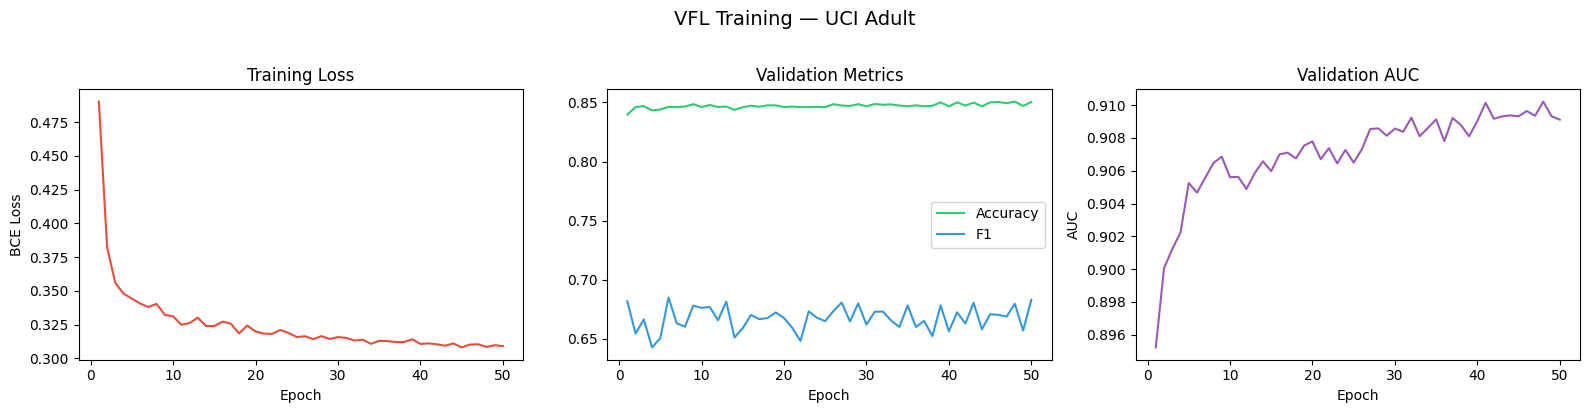

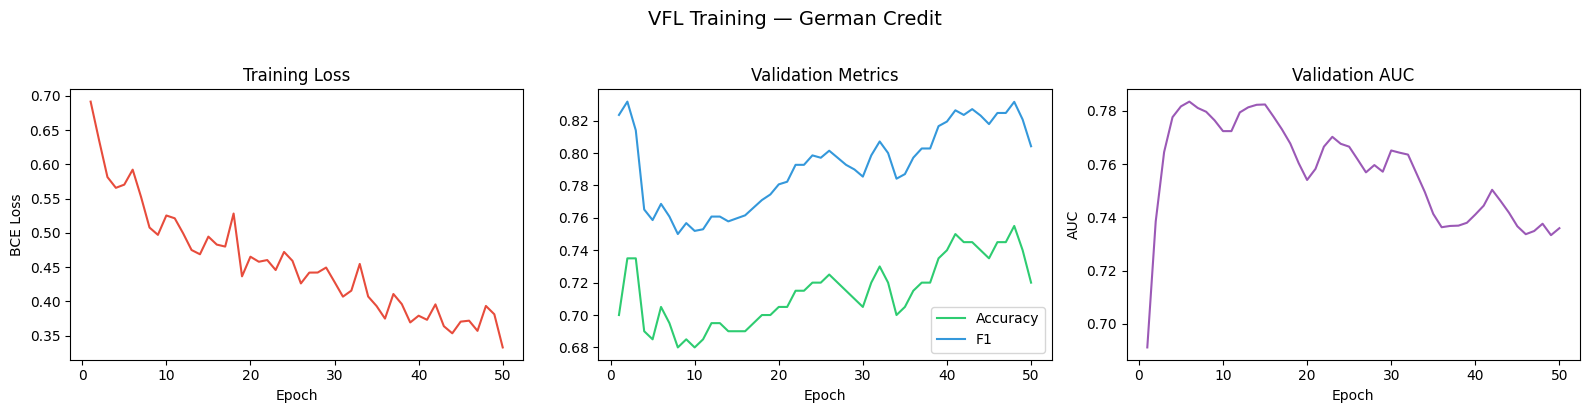

In [ ]:
def plot_training_curves(hist, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    epochs = range(1, len(hist['loss']) + 1)

    axes[0].plot(epochs, hist['loss'], color='#e74c3c')
    axes[0].set_title('Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss')

    axes[1].plot(epochs, hist['acc'], label='Accuracy', color='#2ecc71')
    axes[1].plot(epochs, hist['f1'],  label='F1',       color='#3498db')
    axes[1].set_title('Validation Metrics'); axes[1].set_xlabel('Epoch')
    axes[1].legend()

    axes[2].plot(epochs, hist['auc'], color='#9b59b6')
    axes[2].set_title('Validation AUC'); axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('AUC')

    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{title.replace(' ','_').replace('—','')}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_training_curves(hist_adult,  'VFL Training — UCI Adult')
plot_training_curves(hist_german, 'VFL Training — German Credit')

### 9.4 Unlearning Method Comparison — Bar Charts

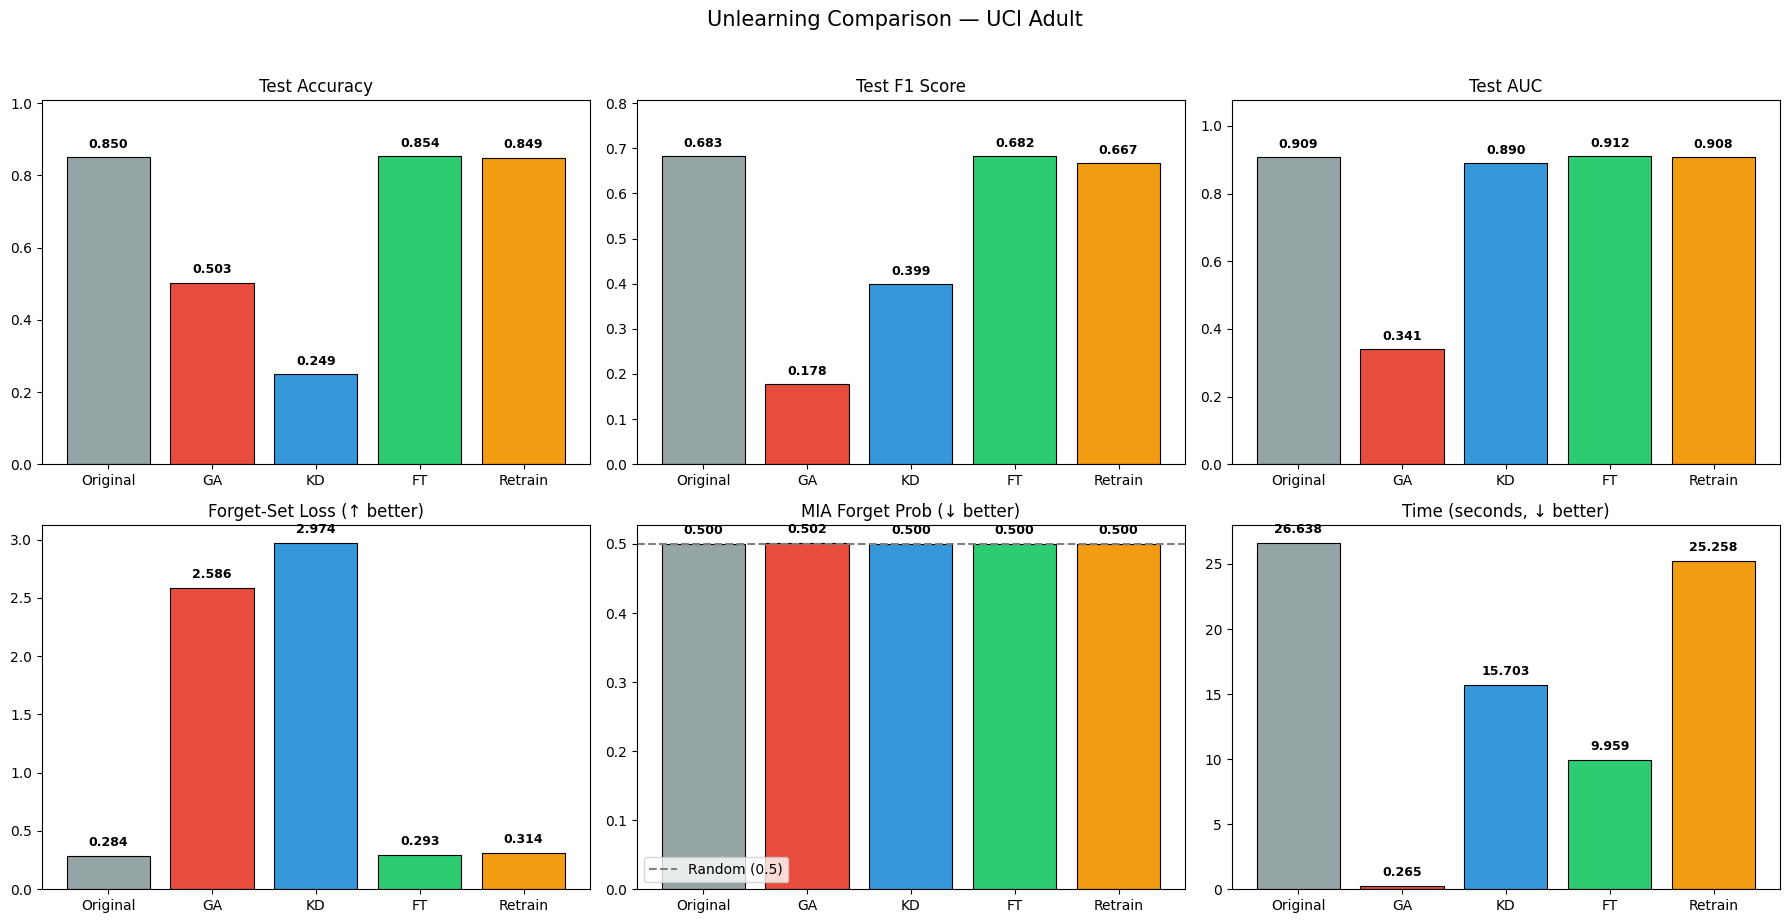

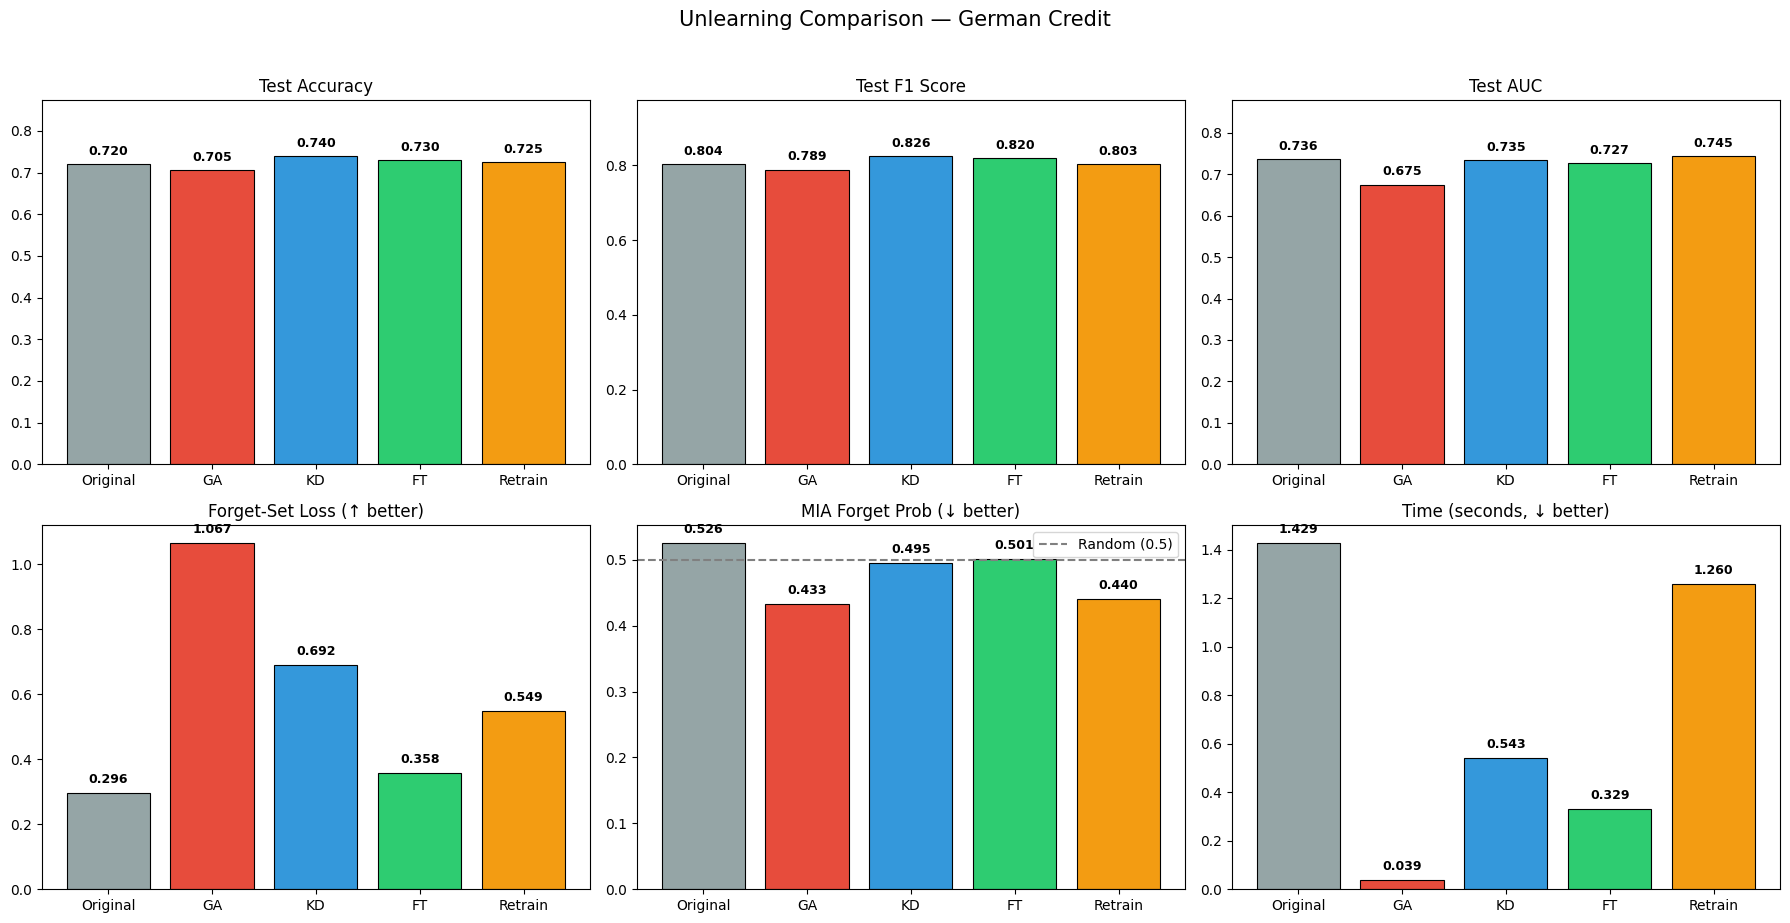

In [ ]:
def plot_comparison_bars(results, dataset_name):
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    colors  = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71', '#f39c12']

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    metrics_top = [('accuracy', 'Test Accuracy'), ('f1', 'Test F1 Score'), ('auc', 'Test AUC')]
    metrics_bot = [('forget_loss', 'Forget-Set Loss (↑ better)'),
                   ('mia_forget_prob', 'MIA Forget Prob (↓ better)'),
                   ('time_s', 'Time (seconds, ↓ better)')]

    for ax, (key, title) in zip(axes[0], metrics_top):
        vals = [results[m][key] for m in methods]
        bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
        ax.set_title(title, fontsize=12)
        ax.set_ylim(0, max(vals) * 1.18)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(vals)*0.02,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    for ax, (key, title) in zip(axes[1], metrics_bot):
        vals = [results[m][key] for m in methods]
        bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
        ax.set_title(title, fontsize=12)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(vals)*0.02,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    # horizontal ref line at 0.5 for MIA
    axes[1][1].axhline(0.5, ls='--', color='gray', label='Random (0.5)')
    axes[1][1].legend()

    fig.suptitle(f'Unlearning Comparison — {dataset_name}', fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Unlearning_Comparison_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_comparison_bars(results_adult,  'UCI Adult')
plot_comparison_bars(results_german, 'German Credit')

### 9.5 Radar / Spider Chart — Multi-Metric View

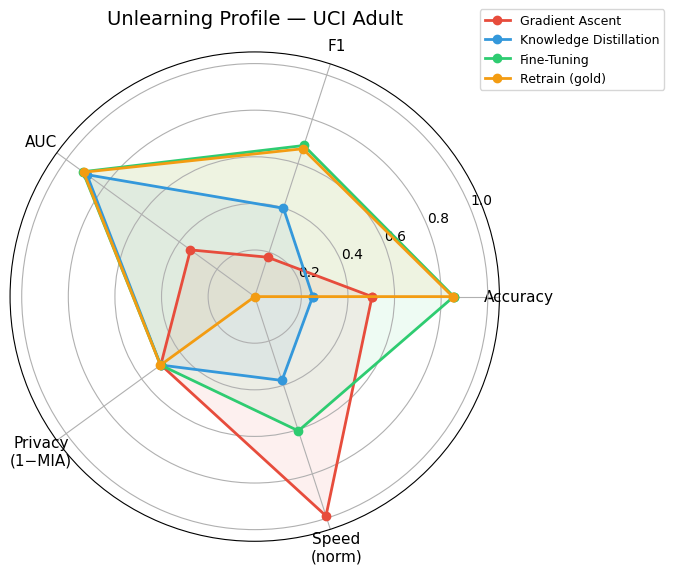

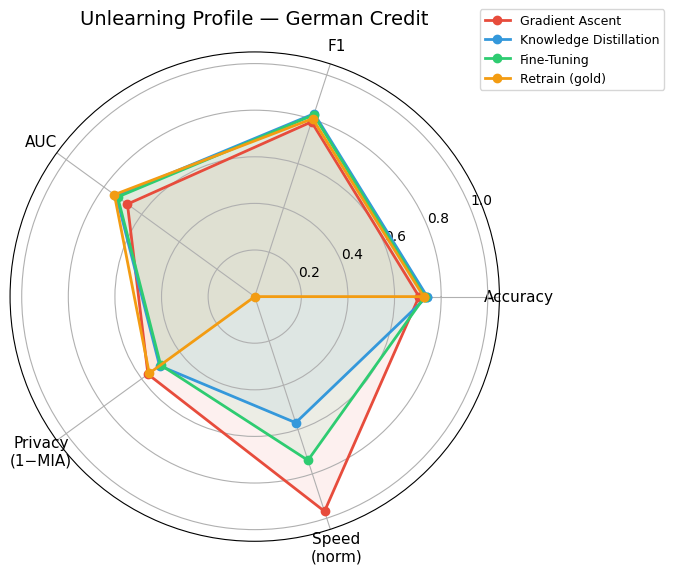

In [ ]:
def plot_radar(results, dataset_name):
    """Radar chart: Accuracy, F1, AUC, 1-MIA_prob (privacy), normalised speed."""
    methods = ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    colors  = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    categories = ['Accuracy', 'F1', 'AUC', 'Privacy\n(1−MIA)', 'Speed\n(norm)']

    max_time = max(results[m]['time_s'] for m in methods)

    angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    for meth, col in zip(methods, colors):
        r = results[meth]
        vals = [
            r['accuracy'],
            r['f1'],
            r['auc'],
            1 - r['mia_forget_prob'],
            1 - r['time_s'] / max(max_time, 1e-9),
        ]
        vals += vals[:1]
        ax.plot(angles, vals, 'o-', label=meth, color=col, linewidth=2)
        ax.fill(angles, vals, alpha=0.08, color=col)

    ax.set_thetagrids(np.degrees(angles[:-1]), categories, fontsize=11)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'Unlearning Profile — {dataset_name}', fontsize=14, pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Radar_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_radar(results_adult,  'UCI Adult')
plot_radar(results_german, 'German Credit')

### 9.6 Heatmap — Cross-Dataset, Cross-Method Comparison

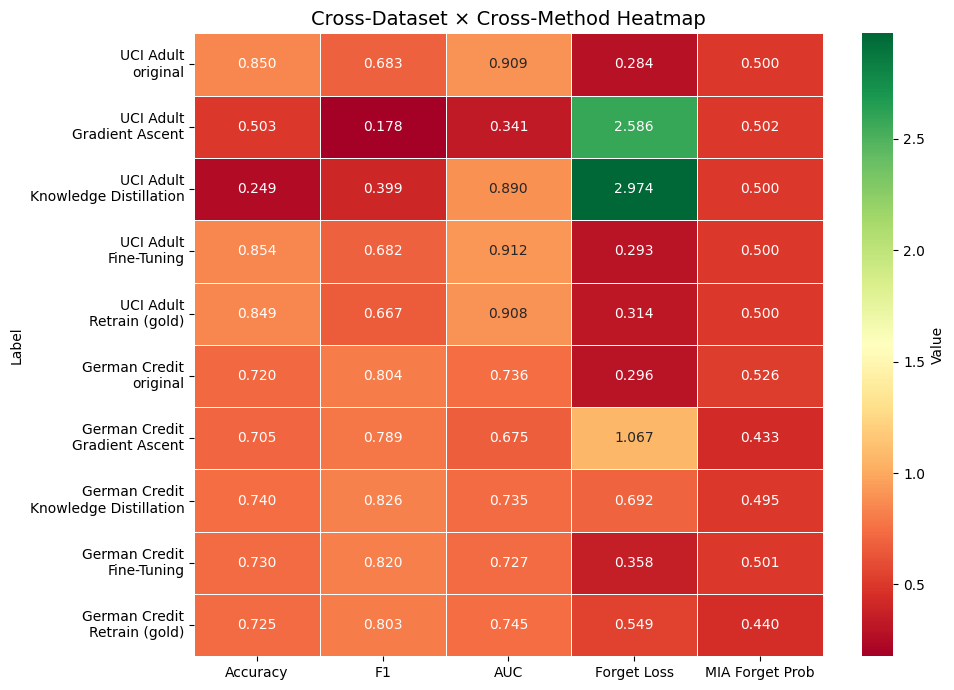

In [ ]:
def plot_heatmap(df_all):
    pivot_metrics = ['Accuracy', 'F1', 'AUC', 'Forget Loss', 'MIA Forget Prob']
    df_sub = df_all[['Dataset', 'Method'] + pivot_metrics].copy()
    df_sub['Label'] = df_sub['Dataset'] + '\n' + df_sub['Method']
    df_sub = df_sub.set_index('Label')[pivot_metrics]

    fig, ax = plt.subplots(figsize=(10, len(df_sub) * 0.6 + 1))
    sns.heatmap(df_sub, annot=True, fmt='.3f', cmap='RdYlGn', linewidths=0.5,
                ax=ax, cbar_kws={'label': 'Value'})
    ax.set_title('Cross-Dataset × Cross-Method Heatmap', fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Heatmap_Cross_Dataset.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_heatmap(df_all)

### 9.7 Privacy–Utility Trade-off Scatter

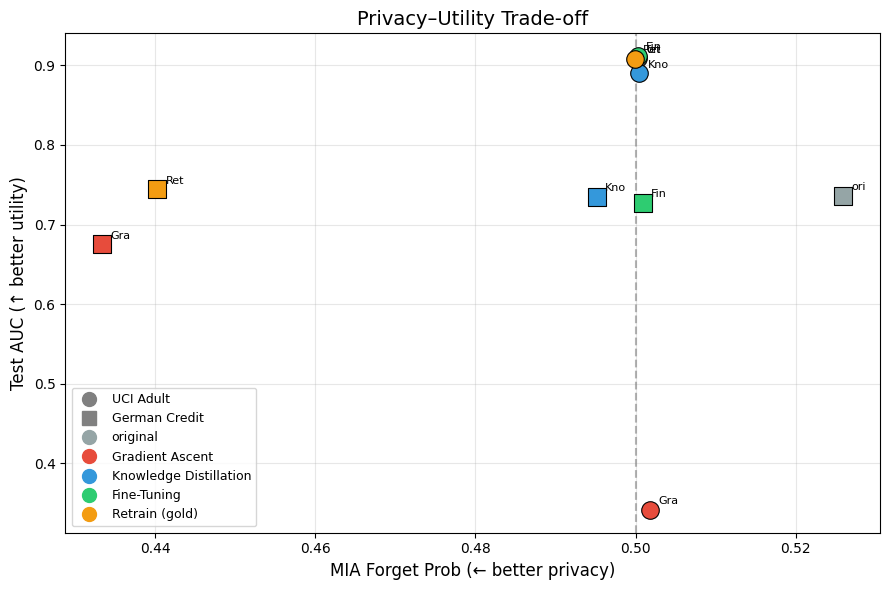

In [ ]:
def plot_privacy_utility(df_all):
    """X = MIA forget prob (lower = better privacy), Y = Test AUC (higher = better utility)."""
    markers = {'UCI Adult': 'o', 'German Credit': 's'}
    colors  = {'original': '#95a5a6', 'Gradient Ascent': '#e74c3c',
               'Knowledge Distillation': '#3498db', 'Fine-Tuning': '#2ecc71',
               'Retrain (gold)': '#f39c12'}

    fig, ax = plt.subplots(figsize=(9, 6))
    for _, row in df_all.iterrows():
        ax.scatter(row['MIA Forget Prob'], row['AUC'],
                   marker=markers[row['Dataset']], color=colors[row['Method']],
                   s=160, edgecolors='black', linewidth=0.8, zorder=5)
        ax.annotate(row['Method'][:3], (row['MIA Forget Prob'], row['AUC']),
                    textcoords='offset points', xytext=(6, 4), fontsize=8)

    ax.axvline(0.5, ls='--', color='gray', alpha=0.6, label='Random MIA (0.5)')
    ax.set_xlabel('MIA Forget Prob (← better privacy)', fontsize=12)
    ax.set_ylabel('Test AUC (↑ better utility)', fontsize=12)
    ax.set_title('Privacy–Utility Trade-off', fontsize=14)

    # custom legend
    from matplotlib.lines import Line2D
    h = [Line2D([0],[0], marker=v, color='gray', ls='', ms=10, label=k)
         for k,v in markers.items()]
    h += [Line2D([0],[0], marker='o', color=c, ls='', ms=10, label=k)
          for k,c in colors.items()]
    ax.legend(handles=h, fontsize=9, loc='lower left')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Privacy_Utility_Tradeoff.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_privacy_utility(df_all)

### 9.8 Timing Comparison

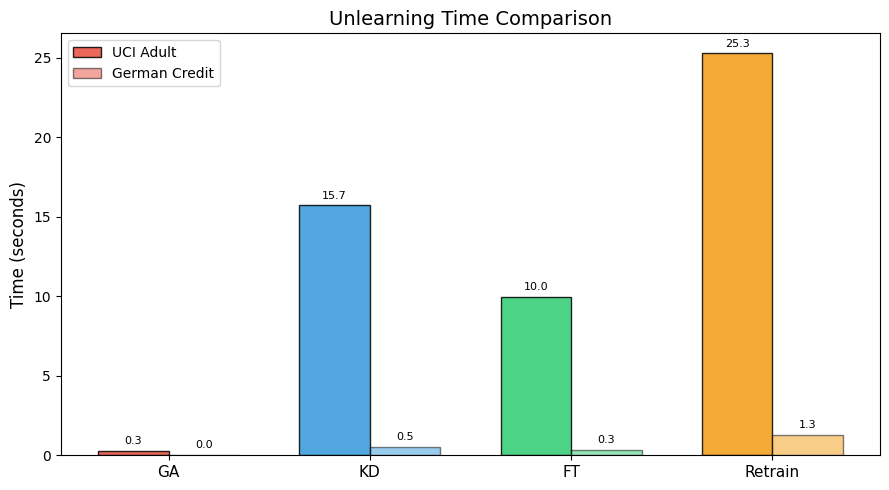

In [ ]:
def plot_timing(results_adult, results_german):
    methods = ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['GA', 'KD', 'FT', 'Retrain']
    colors  = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

    t_adult  = [results_adult[m]['time_s']  for m in methods]
    t_german = [results_german[m]['time_s'] for m in methods]

    x = np.arange(len(labels))
    w = 0.35

    fig, ax = plt.subplots(figsize=(9, 5))
    b1 = ax.bar(x - w/2, t_adult,  w, label='UCI Adult',      color=colors, edgecolor='black', alpha=0.85)
    b2 = ax.bar(x + w/2, t_german, w, label='German Credit',  color=colors, edgecolor='black', alpha=0.50)

    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel('Time (seconds)', fontsize=12)
    ax.set_title('Unlearning Time Comparison', fontsize=14)
    ax.legend(fontsize=10)

    for bars in [b1, b2]:
        for b in bars:
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3,
                    f'{b.get_height():.1f}', ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Timing_Comparison.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_timing(results_adult, results_german)

### 9.9 Forget-Set Loss Distribution (Before vs After Unlearning)

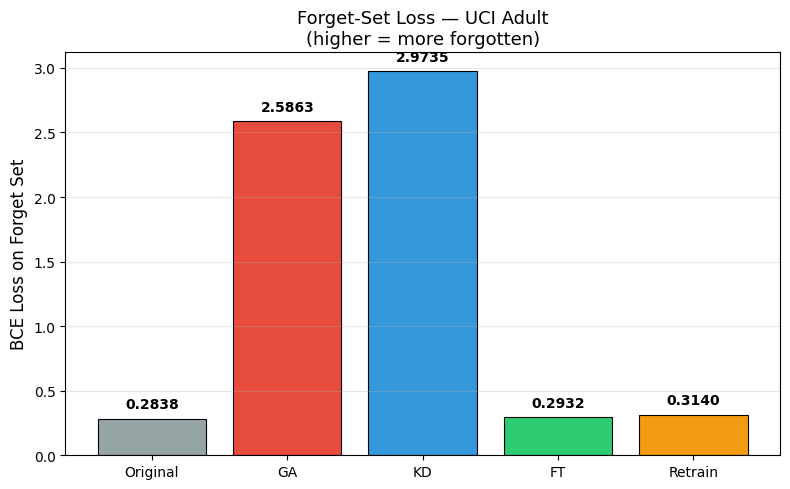

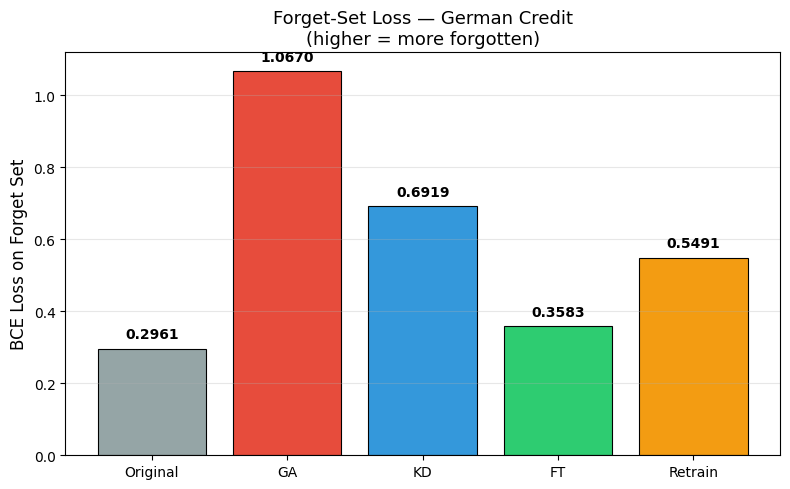

In [ ]:
def plot_forget_loss_comparison(results, dataset_name):
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    colors  = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    vals    = [results[m]['forget_loss'] for m in methods]

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(vals)*0.02,
                f'{v:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylabel('BCE Loss on Forget Set', fontsize=12)
    ax.set_title(f'Forget-Set Loss — {dataset_name}\n(higher = more forgotten)', fontsize=13)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Forget_Loss_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_forget_loss_comparison(results_adult,  'UCI Adult')
plot_forget_loss_comparison(results_german, 'German Credit')

### 9.10 MIA Membership Probability Distribution

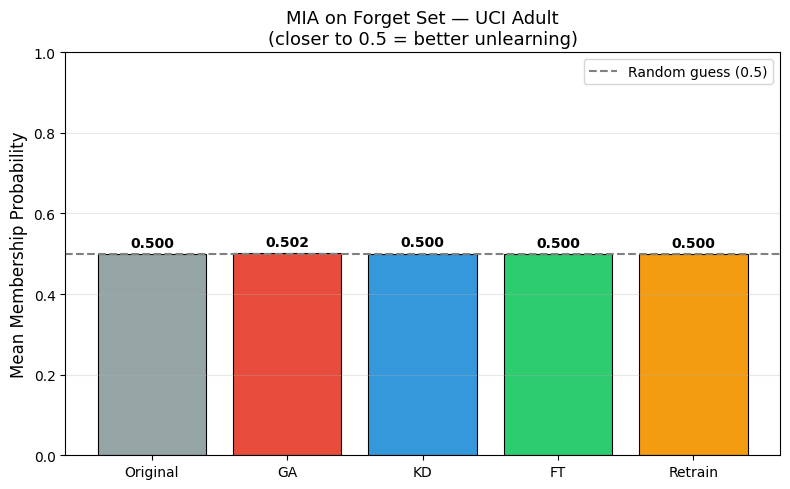

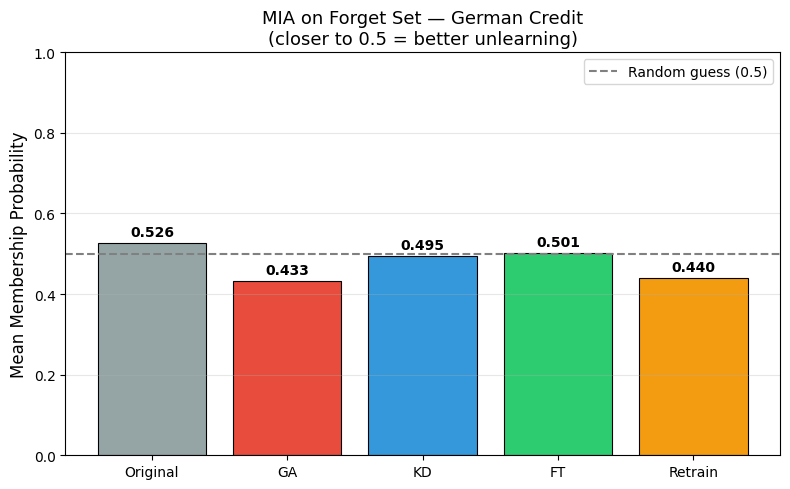

In [ ]:
def plot_mia_comparison(results, dataset_name):
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    colors  = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    vals    = [results[m]['mia_forget_prob'] for m in methods]

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
    ax.axhline(0.5, ls='--', color='gray', label='Random guess (0.5)')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylabel('Mean Membership Probability', fontsize=12)
    ax.set_title(f'MIA on Forget Set — {dataset_name}\n(closer to 0.5 = better unlearning)', fontsize=13)
    ax.set_ylim(0, 1); ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/MIA_Forget_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_mia_comparison(results_adult,  'UCI Adult')
plot_mia_comparison(results_german, 'German Credit')

## 10. Final Summary & Interpretation

In [ ]:
def final_summary(results_adult, results_german):
    print("=" * 85)
    print("  FINAL SUMMARY — VFL UNLEARNING METHODS")
    print("=" * 85)

    for ds_name, res in [('UCI Adult', results_adult), ('German Credit', results_german)]:
        print(f"\n  {'─'*40}")
        print(f"  Dataset: {ds_name}")
        print(f"  {'─'*40}")
        orig = res['original']
        header = f"  {'Method':<28} {'Acc':>7} {'F1':>7} {'AUC':>7} {'FLoss':>8} {'MIA_P':>7} {'Time':>7}"
        print(header)
        print(f"  {'─'*len(header)}")
        order = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
        for m in order:
            r = res[m]
            print(f"  {m:<28} {r['accuracy']:7.4f} {r['f1']:7.4f} {r['auc']:7.4f} "
                  f"{r['forget_loss']:8.4f} {r['mia_forget_prob']:7.4f} {r['time_s']:6.1f}s")

    print(f"\n{'='*85}")
    print("  KEY TAKE-AWAYS")
    print("=" * 85)
    print("""
  1. Gradient Ascent (GA)  — Fastest unlearning. Effectively raises forget-set loss
     and pushes MIA probability toward random. May slightly degrade test accuracy
     because gradient ascent on a subset can perturb global weights.

  2. Knowledge Distillation (KD)  — Produces a fresh student model that never saw
     the forget set. Strong privacy guarantee (low MIA), but takes longer because
     the entire student is trained from scratch on the retain set.

  3. Fine-Tuning (FT)  — A balanced middle ground: overwrites forget-set knowledge
     by continuing training on the retain set. Moderate speed, usually preserves
     utility well. MIA drop depends on the number of fine-tuning epochs.

  4. Retrain (gold standard)  — Full retraining without the forget set. Provides
     the theoretical upper bound on unlearning effectiveness but is the slowest.
     All three approximate methods aim to match retrain quality at lower cost.
""")

final_summary(results_adult, results_german)

  FINAL SUMMARY — VFL UNLEARNING METHODS

  ────────────────────────────────────────
  Dataset: UCI Adult
  ────────────────────────────────────────
  Method                           Acc      F1     AUC    FLoss   MIA_P    Time
  ───────────────────────────────────────────────────────────────────────────────
  original                      0.8503  0.6830  0.9091   0.2838  0.5003   26.6s
  Gradient Ascent               0.5034  0.1778  0.3412   2.5863  0.5019    0.3s
  Knowledge Distillation        0.2490  0.3987  0.8903   2.9735  0.5004   15.7s
  Fine-Tuning                   0.8541  0.6819  0.9117   0.2932  0.5003   10.0s
  Retrain (gold)                0.8493  0.6672  0.9081   0.3140  0.4999   25.3s

  ────────────────────────────────────────
  Dataset: German Credit
  ────────────────────────────────────────
  Method                           Acc      F1     AUC    FLoss   MIA_P    Time
  ───────────────────────────────────────────────────────────────────────────────
  original     

---

## 12. Feature Entanglement Analysis

In VFL the parties' encoders become **entangled** through the shared top model.  
Unlearning one party's data can ripple across all other parties. We quantify this with the **cross-party influence Jacobian** (Varshney et al., 2025):

$$J_{k \to j}[d,\, f] \;=\; \frac{1}{N}\sum_{n=1}^{N} \frac{\partial}{\partial X_k^{(n)}[f]} \left(\frac{\partial \hat{y}^{(n)}}{\partial e_j[d]}\right)$$

By the chain rule through the top model $g$ and party $k$'s bottom model $f_k$:

$$J_{k \to j}[d,\, f] \;=\; \sum_m \frac{\partial^2 g}{\partial e_j[d]\;\partial e_k[m]} \;\cdot\; \frac{\partial f_k(X_k)[m]}{\partial X_k[f]}$$

The first factor is the **top model's mixed Hessian** (how the gradient signal $\partial\hat{y}/\partial e_j$ that party $j$ receives is modulated by $e_k$). The second factor is **party $k$'s bottom-model Jacobian** (how raw features map to embeddings). The entanglement score is:

$$\rho_{k \to j} = \frac{\sigma_1(J_{k \to j})}{\| J_{k \to j} \|_F}$$

$\rho \to 1$: concentrated coupling (HIGH risk) &nbsp;|&nbsp; $\rho \to 0$: negligible coupling (LOW risk).

We measure entanglement at **three granularities** across all **4 parties**:

| Level | What is being unlearned | ρ measures |
|-------|------------------------|------------|
| **Party-level** | All features of a passive party | Cross-party Jacobian $J_{k \to j}$ for every remaining party $j$ |
| **Feature-level** | Individual features inside a party | Per-feature column norm of $J_{k \to j}$ + intra-party Jacobian |
| **Sample-level** | A subset of training samples | Per-sample gradient-norm change before/after unlearning |

### 12.1 Entanglement Infrastructure

In [ ]:
# ---------------------------------------------------------------------------
#  Jacobian-based entanglement utilities (adapted from Part_2 / Algorithm 5)
# ---------------------------------------------------------------------------

TAU_LOW, TAU_HIGH = 0.15, 0.40   # risk thresholds

def _classify_risk(rho):
    if rho < TAU_LOW:   return 'LOW'
    if rho < TAU_HIGH:  return 'MEDIUM'
    return 'HIGH'


def _forward_to_layer(model, x, layer_idx):
    """Forward through a BottomModel up to (and including) the layer_idx-th Linear block."""
    children = list(model.net.children())
    linears = [i for i, c in enumerate(children) if isinstance(c, nn.Linear)]
    end = linears[layer_idx] + 2 if layer_idx < len(linears) - 1 else len(children)
    return nn.Sequential(*children[:min(end, len(children))])(x)


def compute_cross_party_jacobian(vfl_model, X_batch, k, j):
    """
    Cross-party influence Jacobian  J_{k→j}  of shape (d_ej, d_xk).

    Computes:
        J[d, f] = mean_batch( ∂/∂X_k[f]  (∂ŷ/∂e_j[d]) )

    By chain rule this expands to:
        J[d, f] = Σ_m  (∂²g / ∂e_j[d] ∂e_k[m]) · (∂f_k(X_k)[m] / ∂X_k[f])

    where g is the top model, f_k is party k's bottom model, e_k = f_k(X_k).
    The first factor is the top model's mixed Hessian (how the gradient signal
    ∂ŷ/∂e_j that party j receives is modulated by e_k).  The second factor is
    party k's bottom-model Jacobian (how raw features map to embeddings).

    ρ = σ_1(J) / ‖J‖_F  →  1 means concentrated coupling (HIGH risk).
    """
    vfl_model.eval_mode()
    X_k = X_batch[k].detach().requires_grad_(True)

    embeddings, e_j_leaf = [], None
    for i in range(vfl_model.n_parties):
        if i == k:
            emb = vfl_model.bottom_models[i](X_k)       # gradient flows through f_k
        elif i == j:
            with torch.no_grad():
                raw = vfl_model.bottom_models[i](X_batch[i])
            emb = raw.detach().requires_grad_(True)      # e_j treated as leaf
            e_j_leaf = emb
        else:
            with torch.no_grad():
                emb = vfl_model.bottom_models[i](X_batch[i])
        embeddings.append(emb)

    out = vfl_model.top_model(torch.cat(embeddings, dim=1))

    # Step 1:  ∂ŷ/∂e_j  (first-order, with graph retained for second derivative)
    grad_ej = torch.autograd.grad(out.sum(), e_j_leaf,
                                   create_graph=True, retain_graph=True)[0]

    # Step 2:  ∂/∂X_k( ∂ŷ/∂e_j[d] )  for each embedding dimension d
    d_ej, d_xk = e_j_leaf.shape[1], X_k.shape[1]
    J = torch.zeros(d_ej, d_xk, device=X_k.device)
    for d in range(d_ej):
        g2 = torch.autograd.grad(grad_ej[:, d].sum(), X_k, retain_graph=True)[0]
        J[d] = g2.mean(dim=0)
    return J.detach()


def _compute_intra_jacobian_rho(model, X_full, feature_indices, svd_rank, batch_size, device):
    """ρ for the intra-party Jacobian ∂h^(l)/∂F_k per Linear layer."""
    model.eval()
    children = list(model.net.children())
    n_layers = sum(1 for c in children if isinstance(c, nn.Linear))
    n_use = min(X_full.shape[0], batch_size)
    X = X_full[:n_use].detach().requires_grad_(True)
    rho_list = []
    for l in range(n_layers):
        h = _forward_to_layer(model, X, l)
        d_h, d_f = h.shape[1], len(feature_indices)
        J = torch.zeros(d_h, d_f, device=device)
        for i in range(d_h):
            g = torch.autograd.grad(h[:, i].sum(), X, create_graph=False, retain_graph=True)[0]
            for fi_idx, fi in enumerate(feature_indices):
                J[i, fi_idx] = g[:, fi].mean()
        r = min(svd_rank, *J.shape)
        _, S, _ = torch.linalg.svd(J, full_matrices=False)
        S_top = S[:r]
        frob = torch.sqrt((S_top ** 2).sum())
        rho_list.append((S_top[0] / frob).item() if frob > 1e-12 else 0.0)
    return rho_list


# ===========================================================================
#   PARTY-LEVEL entanglement
# ===========================================================================
def party_level_entanglement(vfl_model, X_parties, target_k,
                              svd_rank=10, n_batches=5, batch_size=512):
    """For every remaining party j, compute ρ_{k→j}."""
    remaining = [j for j in range(vfl_model.n_parties) if j != target_k]
    result = {}
    for j in remaining:
        J_acc = None
        for b in range(n_batches):
            s = b * batch_size
            e = min(s + batch_size, X_parties[target_k].shape[0])
            if s >= e: break
            Xb = [X_parties[i][s:e] for i in range(vfl_model.n_parties)]
            Jb = compute_cross_party_jacobian(vfl_model, Xb, target_k, j)
            J_acc = Jb if J_acc is None else J_acc + Jb
        J_acc /= n_batches
        r = min(svd_rank, *J_acc.shape)
        _, S, _ = torch.linalg.svd(J_acc, full_matrices=False)
        S_top = S[:r]
        frob = torch.sqrt((S_top ** 2).sum())
        rho = (S_top[0] / frob).item() if frob > 1e-12 else 0.0
        result[j] = {'rho': rho, 'risk': _classify_risk(rho)}
    return result


# ===========================================================================
#   FEATURE-LEVEL entanglement  (single-party — kept for compatibility)
# ===========================================================================
def feature_level_entanglement(vfl_model, X_parties, target_k,
                                svd_rank=10, n_batches=5, batch_size=512):
    """Per-feature ρ_self (intra-party) + ρ_cross (column-norm ratio) for P_k."""
    k = target_k
    n_feat = X_parties[k].shape[1]
    feat_names = vfl_model.party_data[k].get('features',
                                              [f'f{i}' for i in range(n_feat)])
    remaining = [j for j in range(vfl_model.n_parties) if j != k]

    cross_J = {}
    for j in remaining:
        J_acc = None
        for b in range(n_batches):
            s = b * batch_size
            e = min(s + batch_size, X_parties[k].shape[0])
            if s >= e: break
            Xb = [X_parties[i][s:e] for i in range(vfl_model.n_parties)]
            Jb = compute_cross_party_jacobian(vfl_model, Xb, k, j)
            J_acc = Jb if J_acc is None else J_acc + Jb
        cross_J[j] = J_acc / n_batches

    rows = []
    for f in range(n_feat):
        rho_intra = _compute_intra_jacobian_rho(
            vfl_model.bottom_models[k], X_parties[k], [f], svd_rank, batch_size,
            X_parties[k].device)
        rho_self = float(np.median(rho_intra)) if rho_intra else 0.0

        rho_cross = {}
        for j in remaining:
            col = cross_J[j][:, f]
            cn = torch.sqrt((col ** 2).sum()).item()
            fn = torch.sqrt((cross_J[j] ** 2).sum()).item()
            rho_cross[j] = cn / fn if fn > 1e-12 else 0.0

        scores = [rho_self] + [rho_cross[j] for j in remaining]
        rho_overall = float(np.median(scores))
        rows.append({
            'idx': f,
            'name': feat_names[f] if f < len(feat_names) else f'f{f}',
            'party': k,
            'rho_self': rho_self,
            'rho_cross': rho_cross,
            'rho_overall': rho_overall,
            'risk': _classify_risk(rho_overall),
        })
    return rows


# ===========================================================================
#   ALL-FEATURES entanglement  (every feature from every party)
# ===========================================================================
def all_features_entanglement(vfl_model, X_parties,
                               svd_rank=10, n_batches=5, batch_size=512):
    """
    Analyse EVERY feature across ALL parties.
    For each party p and each of its features f:
      • ρ_self  = intra-party Jacobian (how f drives p's own encoder)
      • ρ_cross = for every other party j, column-norm ratio of J_{p→j}[:, f]
      • ρ_overall = median of all scores
    Returns a flat list of dicts, one per feature, with 'party' and 'name' labels.
    """
    n_parties = vfl_model.n_parties
    rows = []

    for p in range(n_parties):
        n_feat = X_parties[p].shape[1]
        feat_names = vfl_model.party_data[p].get(
            'features', [f'f{i}' for i in range(n_feat)])
        others = [j for j in range(n_parties) if j != p]

        # cross-party Jacobians J_{p→j} for every other party j
        cross_J = {}
        for j in others:
            J_acc = None
            for b in range(n_batches):
                s = b * batch_size
                e = min(s + batch_size, X_parties[p].shape[0])
                if s >= e:
                    break
                Xb = [X_parties[i][s:e] for i in range(n_parties)]
                Jb = compute_cross_party_jacobian(vfl_model, Xb, p, j)
                J_acc = Jb if J_acc is None else J_acc + Jb
            cross_J[j] = J_acc / n_batches

        for f in range(n_feat):
            rho_intra = _compute_intra_jacobian_rho(
                vfl_model.bottom_models[p], X_parties[p], [f],
                svd_rank, batch_size, X_parties[p].device)
            rho_self = float(np.median(rho_intra)) if rho_intra else 0.0

            rho_cross = {}
            for j in others:
                col = cross_J[j][:, f]
                cn = torch.sqrt((col ** 2).sum()).item()
                fn = torch.sqrt((cross_J[j] ** 2).sum()).item()
                rho_cross[j] = cn / fn if fn > 1e-12 else 0.0

            scores = [rho_self] + [rho_cross[j] for j in others]
            rho_overall = float(np.median(scores))

            fname = feat_names[f] if f < len(feat_names) else f'f{f}'
            rows.append({
                'party': p,
                'local_idx': f,
                'name': fname,
                'label': f'P{p}: {fname}',
                'rho_self': rho_self,
                'rho_cross': rho_cross,
                'rho_overall': rho_overall,
                'risk': _classify_risk(rho_overall),
            })
    return rows


# ===========================================================================
#   SAMPLE-LEVEL entanglement  (gradient-norm change)
# ===========================================================================
def sample_level_entanglement(vfl_model, X_parties, y, sample_indices,
                               batch_size=64):
    """
    For each sample in sample_indices, compute the L2 gradient norm of the full
    model parameters w.r.t. that sample's BCE loss.
    Returns an array of per-sample gradient norms.
    """
    vfl_model.eval_mode()
    crit = nn.BCELoss()
    norms = []
    for i in sample_indices:
        xs = [X[i:i+1] for X in X_parties]
        ys = y[i:i+1]
        for m in vfl_model.bottom_models: m.zero_grad()
        vfl_model.top_model.zero_grad()
        out, _ = vfl_model.forward(xs)
        loss = crit(out, ys)
        loss.backward()
        total_norm = 0.0
        for p in vfl_model.get_all_parameters():
            if p.grad is not None:
                total_norm += p.grad.detach().norm(2).item() ** 2
        norms.append(total_norm ** 0.5)
    return np.array(norms)

print("Entanglement infrastructure loaded.")

Entanglement infrastructure loaded.


### 12.2 Full Entanglement Experiment Runner

Trains a VFL model, then for each unlearning method:
1. Restores the original model.
2. Measures **party-level**, **feature-level**, and **sample-level** entanglement **before** unlearning.
3. Applies the unlearning method.
4. Measures all three entanglement levels **after** unlearning.
5. Records Δρ (change) for comparison.

In [ ]:
def run_entanglement_experiment(name, party_data, train_epochs=50,
                                forget_ratio=0.05, target_party=1,
                                ga_epochs=10, kd_epochs=30, ft_epochs=20,
                                n_sample_probe=200,
                                embedding_dim=32, hidden_dim=64):
    """
    Train VFL → for each unlearning method compute party / feature / sample
    entanglement BEFORE and AFTER.  Returns a nested dict of results.
    """
    print(f"\n{'='*80}")
    print(f"  ENTANGLEMENT EXPERIMENT: {name}")
    print(f"{'='*80}\n")

    # ---- train original model ----
    vfl = VFLModel(party_data, embedding_dim, hidden_dim, device)
    trainer = VFLTrainer(vfl, lr=0.001)
    X_tr, X_te, y_tr, y_te, _ = trainer.prepare_data(party_data)
    trainer.train(X_tr, X_te, y_tr, y_te, epochs=train_epochs, verbose=False)
    original_state = vfl.state_dict()
    print(f"  Original model trained ({train_epochs} epochs).")

    # ---- forget / retain indices ----
    n_train = y_tr.shape[0]
    n_forget = max(1, int(n_train * forget_ratio))
    np.random.seed(SEED)
    forget_idx = np.random.choice(n_train, n_forget, replace=False)

    # sub-sample for sample-level probes (speed)
    n_probe = min(n_sample_probe, n_forget)
    probe_idx = forget_idx[:n_probe]

    k = target_party                         # passive party for party/feature analysis

    all_results = {}

    methods = {
        'Gradient Ascent':          ('gradient_ascent', ga_epochs),
        'Knowledge Distillation':   ('knowledge_distillation', kd_epochs),
        'Fine-Tuning':              ('fine_tune', ft_epochs),
    }

    for meth_name, (fn_name, ul_epochs) in methods.items():
        print(f"\n  ── {meth_name} ({ul_epochs} epochs) ──")

        # restore original weights
        vfl.load_state_dict(original_state)
        trainer.optimizer = optim.Adam(vfl.get_all_parameters(), lr=0.001)

        # ---- BEFORE unlearning ----
        party_before    = party_level_entanglement(vfl, X_tr, k)
        feat_before     = feature_level_entanglement(vfl, X_tr, k)
        allfeat_before  = all_features_entanglement(vfl, X_tr)
        sample_before   = sample_level_entanglement(vfl, X_tr, y_tr, probe_idx)

        # ---- apply unlearning ----
        unlearner = VFLUnlearner(vfl, trainer, device)
        getattr(unlearner, fn_name)(X_tr, y_tr, forget_idx, epochs=ul_epochs)

        # ---- AFTER unlearning ----
        party_after    = party_level_entanglement(vfl, X_tr, k)
        feat_after     = feature_level_entanglement(vfl, X_tr, k)
        allfeat_after  = all_features_entanglement(vfl, X_tr)
        sample_after   = sample_level_entanglement(vfl, X_tr, y_tr, probe_idx)

        all_results[meth_name] = {
            'party_before':    party_before,
            'party_after':     party_after,
            'feat_before':     feat_before,
            'feat_after':      feat_after,
            'allfeat_before':  allfeat_before,
            'allfeat_after':   allfeat_after,
            'sample_before':   sample_before,
            'sample_after':    sample_after,
        }

        # quick summary
        for j, pb in party_before.items():
            pa = party_after[j]
            print(f"    Party-level  P_{k}→P_{j}:  ρ {pb['rho']:.4f} ({pb['risk']})  →  "
                  f"ρ {pa['rho']:.4f} ({pa['risk']})   Δρ = {pa['rho']-pb['rho']:+.4f}")
        mean_gnorm_b = sample_before.mean()
        mean_gnorm_a = sample_after.mean()
        print(f"    Sample-level grad-norm:  {mean_gnorm_b:.4f}  →  {mean_gnorm_a:.4f}  "
              f"(Δ = {mean_gnorm_a - mean_gnorm_b:+.4f})")

    return all_results, party_data

### 12.3 Run Entanglement Analysis — UCI Adult

In [ ]:
ent_adult, _ = run_entanglement_experiment(
    "UCI Adult", adult_parties,
    train_epochs=50, forget_ratio=0.05, target_party=1,
    ga_epochs=10, kd_epochs=30, ft_epochs=20,
    n_sample_probe=200,
)


  ENTANGLEMENT EXPERIMENT: UCI Adult

  Original model trained (50 epochs).

  ── Gradient Ascent (10 epochs) ──
    GA epoch   2/10  loss(↑) 0.3107
    GA epoch   4/10  loss(↑) 0.3551
    GA epoch   6/10  loss(↑) 0.4827
    GA epoch   8/10  loss(↑) 0.7393
    GA epoch  10/10  loss(↑) 1.2848
    Party-level  P_1→P_0:  ρ 0.9784 (HIGH)  →  ρ 0.9911 (HIGH)   Δρ = +0.0127
    Party-level  P_1→P_2:  ρ 0.9808 (HIGH)  →  ρ 0.9966 (HIGH)   Δρ = +0.0158
    Party-level  P_1→P_3:  ρ 0.9922 (HIGH)  →  ρ 0.9987 (HIGH)   Δρ = +0.0065
    Sample-level grad-norm:  1.8210  →  8.3811  (Δ = +6.5601)

  ── Knowledge Distillation (30 epochs) ──
    KD epoch   6/30  loss 0.2691
    KD epoch  12/30  loss 0.2678
    KD epoch  18/30  loss 0.2676
    KD epoch  24/30  loss 0.2676
    KD epoch  30/30  loss 0.2674
    Party-level  P_1→P_0:  ρ 0.9784 (HIGH)  →  ρ 0.9986 (HIGH)   Δρ = +0.0202
    Party-level  P_1→P_2:  ρ 0.9808 (HIGH)  →  ρ 0.9947 (HIGH)   Δρ = +0.0139
    Party-level  P_1→P_3:  ρ 0.9922 (HIGH)  →

### 12.4 Run Entanglement Analysis — German Credit

In [ ]:
ent_german, _ = run_entanglement_experiment(
    "German Credit", german_parties,
    train_epochs=50, forget_ratio=0.05, target_party=1,
    ga_epochs=10, kd_epochs=30, ft_epochs=20,
    n_sample_probe=40,      # smaller dataset → fewer probes
)


  ENTANGLEMENT EXPERIMENT: German Credit

  Original model trained (50 epochs).

  ── Gradient Ascent (10 epochs) ──
    GA epoch   2/10  loss(↑) 0.2798
    GA epoch   4/10  loss(↑) 0.4753
    GA epoch   6/10  loss(↑) 0.4809
    GA epoch   8/10  loss(↑) 0.6843
    GA epoch  10/10  loss(↑) 0.8446
    Party-level  P_1→P_0:  ρ 0.8812 (HIGH)  →  ρ 0.9249 (HIGH)   Δρ = +0.0437
    Party-level  P_1→P_2:  ρ 0.8140 (HIGH)  →  ρ 0.9503 (HIGH)   Δρ = +0.1364
    Party-level  P_1→P_3:  ρ 0.8509 (HIGH)  →  ρ 0.9189 (HIGH)   Δρ = +0.0679
    Sample-level grad-norm:  4.6527  →  10.3707  (Δ = +5.7181)

  ── Knowledge Distillation (30 epochs) ──
    KD epoch   6/30  loss 0.3477
    KD epoch  12/30  loss 0.3076
    KD epoch  18/30  loss 0.2796
    KD epoch  24/30  loss 0.2598
    KD epoch  30/30  loss 0.2479
    Party-level  P_1→P_0:  ρ 0.8812 (HIGH)  →  ρ 0.9534 (HIGH)   Δρ = +0.0722
    Party-level  P_1→P_2:  ρ 0.8140 (HIGH)  →  ρ 0.9489 (HIGH)   Δρ = +0.1349
    Party-level  P_1→P_3:  ρ 0.8509 (HIG

### 12.5 Party-Level Entanglement — Before vs After (All Methods × Both Datasets)

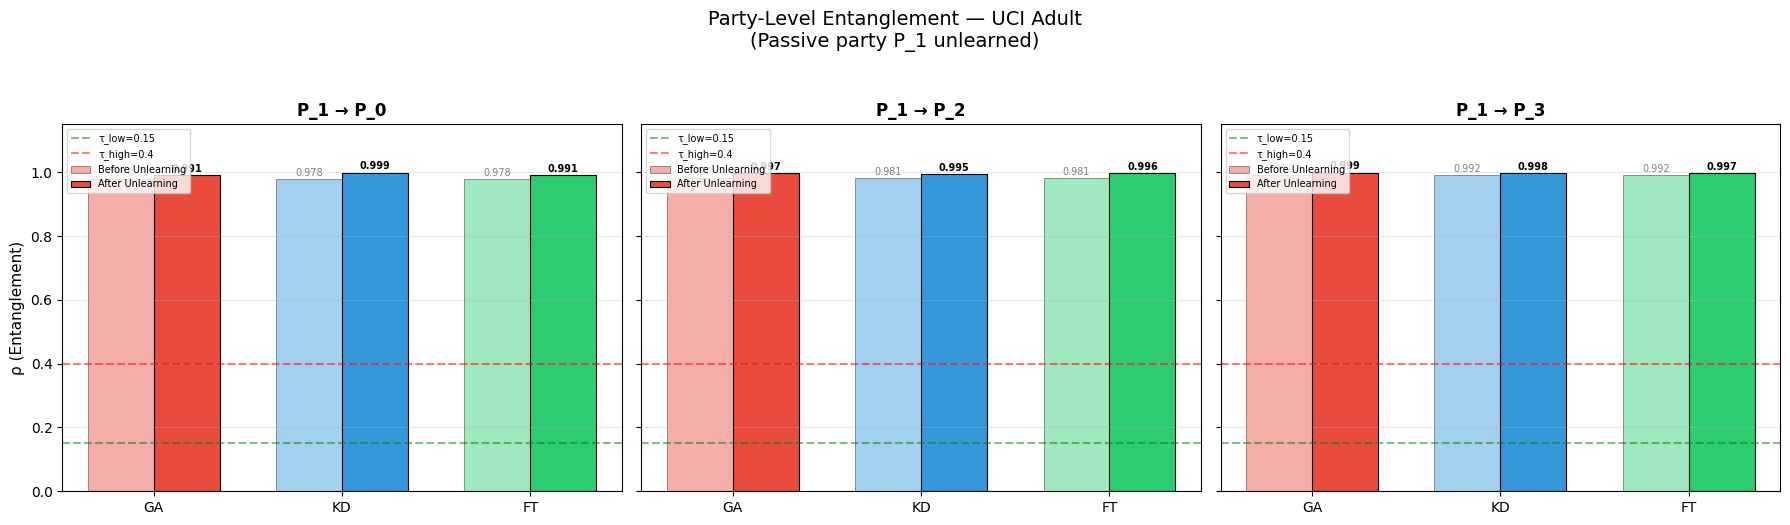

,Dataset,Method,Party Pair,ρ Before,Risk Before,ρ After,Risk After,Δρ
0,UCI Adult,Gradient Ascent,P_1→P_0,0.9784,HIGH,0.9911,HIGH,+0.0127
1,UCI Adult,Gradient Ascent,P_1→P_2,0.9808,HIGH,0.9966,HIGH,+0.0158
2,UCI Adult,Gradient Ascent,P_1→P_3,0.9922,HIGH,0.9987,HIGH,+0.0065
3,UCI Adult,Knowledge Distillation,P_1→P_0,0.9784,HIGH,0.9986,HIGH,+0.0202
4,UCI Adult,Knowledge Distillation,P_1→P_2,0.9808,HIGH,0.9947,HIGH,+0.0139
5,UCI Adult,Knowledge Distillation,P_1→P_3,0.9922,HIGH,0.9978,HIGH,+0.0056
6,UCI Adult,Fine-Tuning,P_1→P_0,0.9784,HIGH,0.9910,HIGH,+0.0125
7,UCI Adult,Fine-Tuning,P_1→P_2,0.9808,HIGH,0.9960,HIGH,+0.0152
8,UCI Adult,Fine-Tuning,P_1→P_3,0.9922,HIGH,0.9973,HIGH,+0.0051


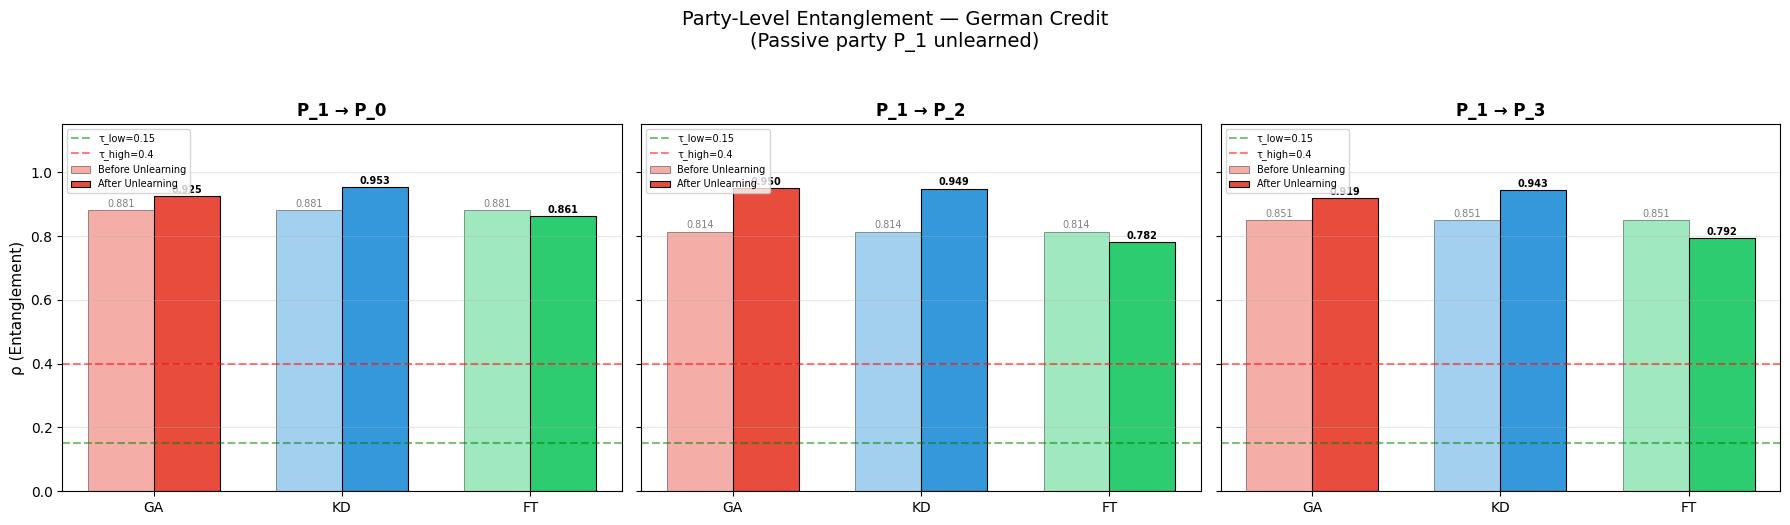

,Dataset,Method,Party Pair,ρ Before,Risk Before,ρ After,Risk After,Δρ
0,German Credit,Gradient Ascent,P_1→P_0,0.8812,HIGH,0.9249,HIGH,+0.0437
1,German Credit,Gradient Ascent,P_1→P_2,0.8140,HIGH,0.9503,HIGH,+0.1364
2,German Credit,Gradient Ascent,P_1→P_3,0.8509,HIGH,0.9189,HIGH,+0.0679
3,German Credit,Knowledge Distillation,P_1→P_0,0.8812,HIGH,0.9534,HIGH,+0.0722
4,German Credit,Knowledge Distillation,P_1→P_2,0.8140,HIGH,0.9489,HIGH,+0.1349
5,German Credit,Knowledge Distillation,P_1→P_3,0.8509,HIGH,0.9435,HIGH,+0.0925
6,German Credit,Fine-Tuning,P_1→P_0,0.8812,HIGH,0.8615,HIGH,-0.0197
7,German Credit,Fine-Tuning,P_1→P_2,0.8140,HIGH,0.7816,HIGH,-0.0324
8,German Credit,Fine-Tuning,P_1→P_3,0.8509,HIGH,0.7922,HIGH,-0.0587


In [ ]:
def plot_party_level_entanglement(ent_results, dataset_name, target_k=1):
    """Grouped bar chart: ρ before / after for each method and each remaining party."""
    methods = list(ent_results.keys())
    remaining_parties = sorted(ent_results[methods[0]]['party_before'].keys())
    n_methods = len(methods)
    n_parties = len(remaining_parties)
    meth_colors = {'Gradient Ascent': '#e74c3c',
                   'Knowledge Distillation': '#3498db',
                   'Fine-Tuning': '#2ecc71'}

    fig, axes = plt.subplots(1, n_parties, figsize=(6 * n_parties, 5), sharey=True)
    if n_parties == 1:
        axes = [axes]

    for pidx, j in enumerate(remaining_parties):
        ax = axes[pidx]
        x = np.arange(n_methods)
        w = 0.35
        rho_b = [ent_results[m]['party_before'][j]['rho'] for m in methods]
        rho_a = [ent_results[m]['party_after'][j]['rho']  for m in methods]
        colors = [meth_colors[m] for m in methods]

        bars_b = ax.bar(x - w/2, rho_b, w, label='Before Unlearning',
                        color=colors, alpha=0.45, edgecolor='black', linewidth=0.6)
        bars_a = ax.bar(x + w/2, rho_a, w, label='After Unlearning',
                        color=colors, edgecolor='black', linewidth=0.8)

        ax.axhline(TAU_LOW,  ls='--', color='green', alpha=0.5, label=f'τ_low={TAU_LOW}')
        ax.axhline(TAU_HIGH, ls='--', color='red',   alpha=0.5, label=f'τ_high={TAU_HIGH}')

        for b, v in zip(bars_b, rho_b):
            ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
                    f'{v:.3f}', ha='center', fontsize=7, color='gray')
        for b, v in zip(bars_a, rho_a):
            ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
                    f'{v:.3f}', ha='center', fontsize=7, fontweight='bold')

        ax.set_xticks(x)
        ax.set_xticklabels(['GA', 'KD', 'FT'], fontsize=10)
        ax.set_title(f'P_{target_k} → P_{j}', fontsize=12, fontweight='bold')
        ax.set_ylim(0, 1.15)
        if pidx == 0:
            ax.set_ylabel('ρ (Entanglement)', fontsize=11)
        ax.legend(fontsize=7, loc='upper left')
        ax.grid(axis='y', alpha=0.3)

    fig.suptitle(f'Party-Level Entanglement — {dataset_name}\n'
                 f'(Passive party P_{target_k} unlearned)',
                 fontsize=14, y=1.04)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Party_Entanglement_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

    # ---- Table ----
    rows = []
    for m in methods:
        for j in remaining_parties:
            pb = ent_results[m]['party_before'][j]
            pa = ent_results[m]['party_after'][j]
            rows.append({
                'Dataset': dataset_name, 'Method': m,
                'Party Pair': f'P_{target_k}→P_{j}',
                'ρ Before': pb['rho'], 'Risk Before': pb['risk'],
                'ρ After':  pa['rho'], 'Risk After':  pa['risk'],
                'Δρ': pa['rho'] - pb['rho'],
            })
    df = pd.DataFrame(rows)
    display(df.style.format({
        'ρ Before': '{:.4f}', 'ρ After': '{:.4f}', 'Δρ': '{:+.4f}'
    }).set_caption(f"Party-Level Entanglement — {dataset_name}"))

plot_party_level_entanglement(ent_adult,  'UCI Adult',      target_k=1)
plot_party_level_entanglement(ent_german, 'German Credit',  target_k=1)

### 12.6 Feature-Level Entanglement — Per-Feature ρ Before vs After

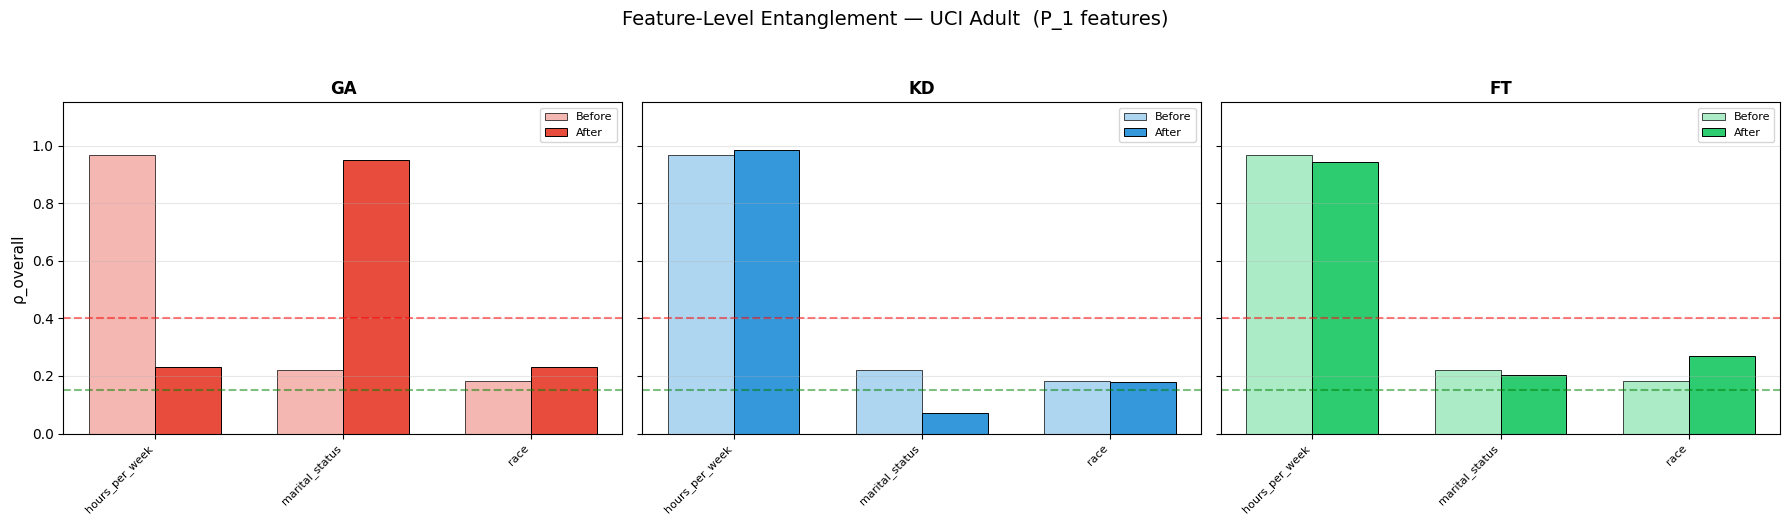

,Dataset,Method,Feature,ρ_self Before,ρ_overall Before,Risk Before,ρ_self After,ρ_overall After,Risk After,Δρ_overall
0,UCI Adult,Gradient Ascent,hours_per_week,1.0000,0.9663,HIGH,1.0000,0.2304,MEDIUM,-0.7359
1,UCI Adult,Gradient Ascent,marital_status,1.0000,0.2219,MEDIUM,1.0000,0.9504,HIGH,+0.7285
2,UCI Adult,Gradient Ascent,race,1.0000,0.1818,MEDIUM,1.0000,0.2311,MEDIUM,+0.0493
3,UCI Adult,Knowledge Distillation,hours_per_week,1.0000,0.9663,HIGH,1.0000,0.9862,HIGH,+0.0199
4,UCI Adult,Knowledge Distillation,marital_status,1.0000,0.2219,MEDIUM,1.0000,0.0703,LOW,-0.1516
5,UCI Adult,Knowledge Distillation,race,1.0000,0.1818,MEDIUM,1.0000,0.1779,MEDIUM,-0.0039
6,UCI Adult,Fine-Tuning,hours_per_week,1.0000,0.9663,HIGH,1.0000,0.9439,HIGH,-0.0224
7,UCI Adult,Fine-Tuning,marital_status,1.0000,0.2219,MEDIUM,1.0000,0.2020,MEDIUM,-0.0200
8,UCI Adult,Fine-Tuning,race,1.0000,0.1818,MEDIUM,1.0000,0.2702,MEDIUM,+0.0884


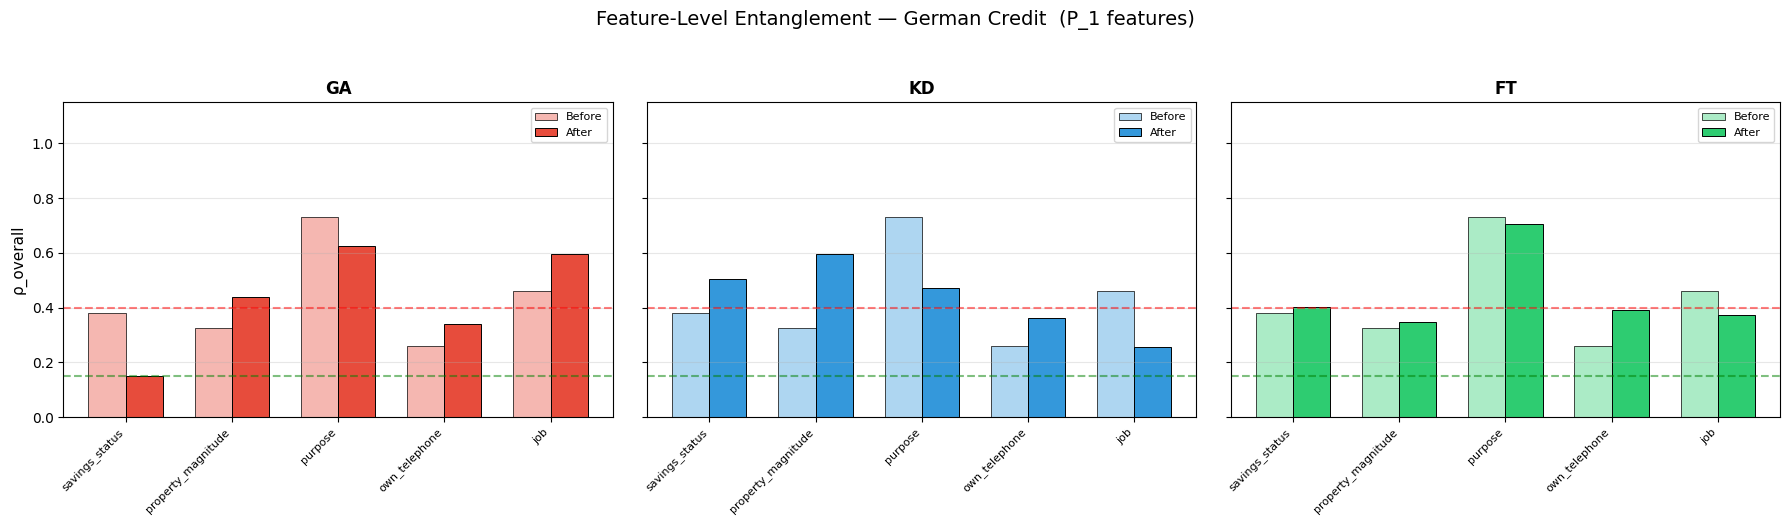

,Dataset,Method,Feature,ρ_self Before,ρ_overall Before,Risk Before,ρ_self After,ρ_overall After,Risk After,Δρ_overall
0,German Credit,Gradient Ascent,savings_status,1.0000,0.3790,MEDIUM,1.0000,0.1500,MEDIUM,-0.2289
1,German Credit,Gradient Ascent,property_magnitude,1.0000,0.3258,MEDIUM,1.0000,0.4383,HIGH,+0.1125
2,German Credit,Gradient Ascent,purpose,1.0000,0.7325,HIGH,1.0000,0.6243,HIGH,-0.1083
3,German Credit,Gradient Ascent,own_telephone,1.0000,0.2609,MEDIUM,1.0000,0.3390,MEDIUM,+0.0781
4,German Credit,Gradient Ascent,job,1.0000,0.4594,HIGH,1.0000,0.5956,HIGH,+0.1362
5,German Credit,Knowledge Distillation,savings_status,1.0000,0.3790,MEDIUM,1.0000,0.5028,HIGH,+0.1238
6,German Credit,Knowledge Distillation,property_magnitude,1.0000,0.3258,MEDIUM,1.0000,0.5972,HIGH,+0.2714
7,German Credit,Knowledge Distillation,purpose,1.0000,0.7325,HIGH,1.0000,0.4734,HIGH,-0.2592
8,German Credit,Knowledge Distillation,own_telephone,1.0000,0.2609,MEDIUM,1.0000,0.3625,MEDIUM,+0.1016
9,German Credit,Knowledge Distillation,job,1.0000,0.4594,HIGH,1.0000,0.2545,MEDIUM,-0.2048


In [ ]:
def plot_feature_level_entanglement(ent_results, dataset_name, target_k=1):
    """One subplot per method: grouped bars ρ_overall before/after for each feature."""
    methods = list(ent_results.keys())
    meth_short = {'Gradient Ascent': 'GA', 'Knowledge Distillation': 'KD', 'Fine-Tuning': 'FT'}
    meth_colors_b = {'Gradient Ascent': '#f5b7b1',
                     'Knowledge Distillation': '#aed6f1',
                     'Fine-Tuning': '#abebc6'}
    meth_colors_a = {'Gradient Ascent': '#e74c3c',
                     'Knowledge Distillation': '#3498db',
                     'Fine-Tuning': '#2ecc71'}

    feat_names = [r['name'] for r in ent_results[methods[0]]['feat_before']]
    n_feat = len(feat_names)

    fig, axes = plt.subplots(1, len(methods), figsize=(6 * len(methods), 5), sharey=True)
    if len(methods) == 1: axes = [axes]

    all_rows = []
    for midx, m in enumerate(methods):
        ax = axes[midx]
        fb = ent_results[m]['feat_before']
        fa = ent_results[m]['feat_after']
        rho_b = [r['rho_overall'] for r in fb]
        rho_a = [r['rho_overall'] for r in fa]
        risk_b = [r['risk'] for r in fb]
        risk_a = [r['risk'] for r in fa]

        x = np.arange(n_feat)
        w = 0.35
        ax.bar(x - w/2, rho_b, w, label='Before', color=meth_colors_b[m],
               edgecolor='black', linewidth=0.5)
        ax.bar(x + w/2, rho_a, w, label='After',  color=meth_colors_a[m],
               edgecolor='black', linewidth=0.7)

        ax.axhline(TAU_LOW,  ls='--', color='green', alpha=0.5)
        ax.axhline(TAU_HIGH, ls='--', color='red',   alpha=0.5)

        ax.set_xticks(x)
        ax.set_xticklabels(feat_names, rotation=45, ha='right', fontsize=8)
        ax.set_title(f'{meth_short[m]}', fontsize=12, fontweight='bold')
        ax.set_ylim(0, 1.15)
        if midx == 0:
            ax.set_ylabel('ρ_overall', fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(axis='y', alpha=0.3)

        for i in range(n_feat):
            all_rows.append({
                'Dataset': dataset_name, 'Method': m,
                'Feature': feat_names[i],
                'ρ_self Before':    fb[i]['rho_self'],
                'ρ_overall Before': fb[i]['rho_overall'],
                'Risk Before':      fb[i]['risk'],
                'ρ_self After':     fa[i]['rho_self'],
                'ρ_overall After':  fa[i]['rho_overall'],
                'Risk After':       fa[i]['risk'],
                'Δρ_overall':       fa[i]['rho_overall'] - fb[i]['rho_overall'],
            })

    fig.suptitle(f'Feature-Level Entanglement — {dataset_name}  (P_{target_k} features)',
                 fontsize=14, y=1.04)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Feature_Entanglement_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

    df = pd.DataFrame(all_rows)
    display(df.style.format({
        'ρ_self Before':'{:.4f}', 'ρ_overall Before':'{:.4f}',
        'ρ_self After':'{:.4f}',  'ρ_overall After':'{:.4f}',
        'Δρ_overall':'{:+.4f}',
    }).set_caption(f"Feature-Level Entanglement — {dataset_name}"))

plot_feature_level_entanglement(ent_adult,  'UCI Adult',     target_k=1)
plot_feature_level_entanglement(ent_german, 'German Credit', target_k=1)

### 12.6b All-Features Entanglement — Every Feature Across All Parties (UCI Adult)

Shows ρ_overall for **all 14 UCI Adult features** grouped and color-coded by their owning party, before and after each unlearning method.

In [ ]:
def plot_all_features_entanglement(ent_results, dataset_name):
    """
    Full-width bar chart of ρ_overall for EVERY feature across ALL parties,
    before and after each unlearning method.  Features are color-coded by party.
    """
    methods = list(ent_results.keys())
    meth_short = {'Gradient Ascent': 'GA', 'Knowledge Distillation': 'KD', 'Fine-Tuning': 'FT'}

    party_cmap = {0: '#e74c3c', 1: '#3498db', 2: '#2ecc71', 3: '#f39c12',
                  4: '#9b59b6', 5: '#1abc9c', 6: '#e67e22', 7: '#34495e'}

    n_methods = len(methods)
    fig, axes = plt.subplots(n_methods, 1,
                             figsize=(max(14, len(ent_results[methods[0]]['allfeat_before']) * 0.9),
                                      4.5 * n_methods),
                             sharex=True)
    if n_methods == 1:
        axes = [axes]

    all_table_rows = []

    for midx, m in enumerate(methods):
        ax = axes[midx]
        fb = ent_results[m]['allfeat_before']
        fa = ent_results[m]['allfeat_after']
        n_feat = len(fb)

        labels   = [r['label'] for r in fb]
        parties  = [r['party'] for r in fb]
        rho_b    = [r['rho_overall'] for r in fb]
        rho_a    = [r['rho_overall'] for r in fa]
        risk_b   = [r['risk'] for r in fb]
        risk_a   = [r['risk'] for r in fa]

        x = np.arange(n_feat)
        w = 0.38

        colors_b = [party_cmap.get(p, '#95a5a6') for p in parties]
        colors_a = [party_cmap.get(p, '#95a5a6') for p in parties]

        ax.bar(x - w/2, rho_b, w, label='Before Unlearning',
               color=colors_b, alpha=0.40, edgecolor='black', linewidth=0.4)
        ax.bar(x + w/2, rho_a, w, label='After Unlearning',
               color=colors_a, alpha=0.85, edgecolor='black', linewidth=0.5)

        ax.axhline(TAU_LOW,  ls='--', color='green', alpha=0.5, label=f'τ_low={TAU_LOW}')
        ax.axhline(TAU_HIGH, ls='--', color='red',   alpha=0.5, label=f'τ_high={TAU_HIGH}')

        for i in range(n_feat):
            ax.text(x[i] - w/2, rho_b[i] + 0.01, f'{rho_b[i]:.2f}',
                    ha='center', fontsize=5.5, color='gray', rotation=90)
            ax.text(x[i] + w/2, rho_a[i] + 0.01, f'{rho_a[i]:.2f}',
                    ha='center', fontsize=5.5, fontweight='bold', rotation=90)

        ax.set_ylabel('ρ_overall', fontsize=11)
        ax.set_ylim(0, 1.25)
        ax.set_title(f'{meth_short[m]}', fontsize=13, fontweight='bold')
        ax.legend(fontsize=7, loc='upper right', ncol=2)
        ax.grid(axis='y', alpha=0.25)

        for i in range(n_feat):
            all_table_rows.append({
                'Dataset': dataset_name, 'Method': m,
                'Party': f'P{parties[i]}', 'Feature': fb[i]['name'],
                'ρ_self Before':    fb[i]['rho_self'],
                'ρ_overall Before': fb[i]['rho_overall'],
                'Risk Before':      fb[i]['risk'],
                'ρ_self After':     fa[i]['rho_self'],
                'ρ_overall After':  fa[i]['rho_overall'],
                'Risk After':       fa[i]['risk'],
                'Δρ_overall':       fa[i]['rho_overall'] - fb[i]['rho_overall'],
            })

    axes[-1].set_xticks(np.arange(len(labels)))
    axes[-1].set_xticklabels(labels, rotation=55, ha='right', fontsize=8)

    # party-colour legend
    from matplotlib.patches import Patch
    unique_parties = sorted(set(parties))
    legend_patches = [Patch(facecolor=party_cmap.get(p, '#95a5a6'), edgecolor='black',
                            label=f'Party {p}') for p in unique_parties]
    fig.legend(handles=legend_patches, loc='lower center', ncol=len(unique_parties),
               fontsize=9, title='Feature owner', title_fontsize=10,
               bbox_to_anchor=(0.5, -0.02))

    fig.suptitle(f'All-Features Entanglement — {dataset_name}\n'
                 f'(All {len(labels)} features across {len(unique_parties)} parties)',
                 fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/All_Features_Entanglement_{dataset_name.replace(' ','_')}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

    df = pd.DataFrame(all_table_rows)
    display(df.style.format({
        'ρ_self Before':'{:.4f}', 'ρ_overall Before':'{:.4f}',
        'ρ_self After':'{:.4f}',  'ρ_overall After':'{:.4f}',
        'Δρ_overall':'{:+.4f}',
    }).set_caption(f"All-Features Entanglement — {dataset_name}"))
    return df

df_allfeat_adult  = plot_all_features_entanglement(ent_adult,  'UCI Adult')
df_allfeat_german = plot_all_features_entanglement(ent_german, 'German Credit')

### 12.6c All-Features Entanglement Heatmap (ρ After Unlearning)

In [ ]:
def plot_allfeat_heatmap(ent_results, dataset_name):
    """Heatmap: features (rows) × methods (columns) showing ρ_overall after unlearning."""
    methods = list(ent_results.keys())
    meth_short = {'Gradient Ascent': 'GA', 'Knowledge Distillation': 'KD', 'Fine-Tuning': 'FT'}

    labels = [r['label'] for r in ent_results[methods[0]]['allfeat_after']]
    data = {}
    for m in methods:
        fa = ent_results[m]['allfeat_after']
        data[meth_short[m] + ' ρ_after'] = [r['rho_overall'] for r in fa]
        fb = ent_results[m]['allfeat_before']
        data[meth_short[m] + ' Δρ'] = [fa[i]['rho_overall'] - fb[i]['rho_overall']
                                        for i in range(len(fa))]

    df = pd.DataFrame(data, index=labels)

    fig, ax = plt.subplots(figsize=(10, max(4, len(labels) * 0.38)))
    sns.heatmap(df, annot=True, fmt='.3f', cmap='RdYlGn_r', linewidths=0.4,
                ax=ax, cbar_kws={'label': 'Value'})
    ax.set_title(f'All-Features Entanglement Heatmap — {dataset_name}', fontsize=13)
    ax.set_ylabel('Feature (Party: Name)')
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/All_Features_Heatmap_{dataset_name.replace(' ','_')}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

plot_allfeat_heatmap(ent_adult,  'UCI Adult')
plot_allfeat_heatmap(ent_german, 'German Credit')

### 12.7 Sample-Level Entanglement — Gradient-Norm Distributions Before vs After

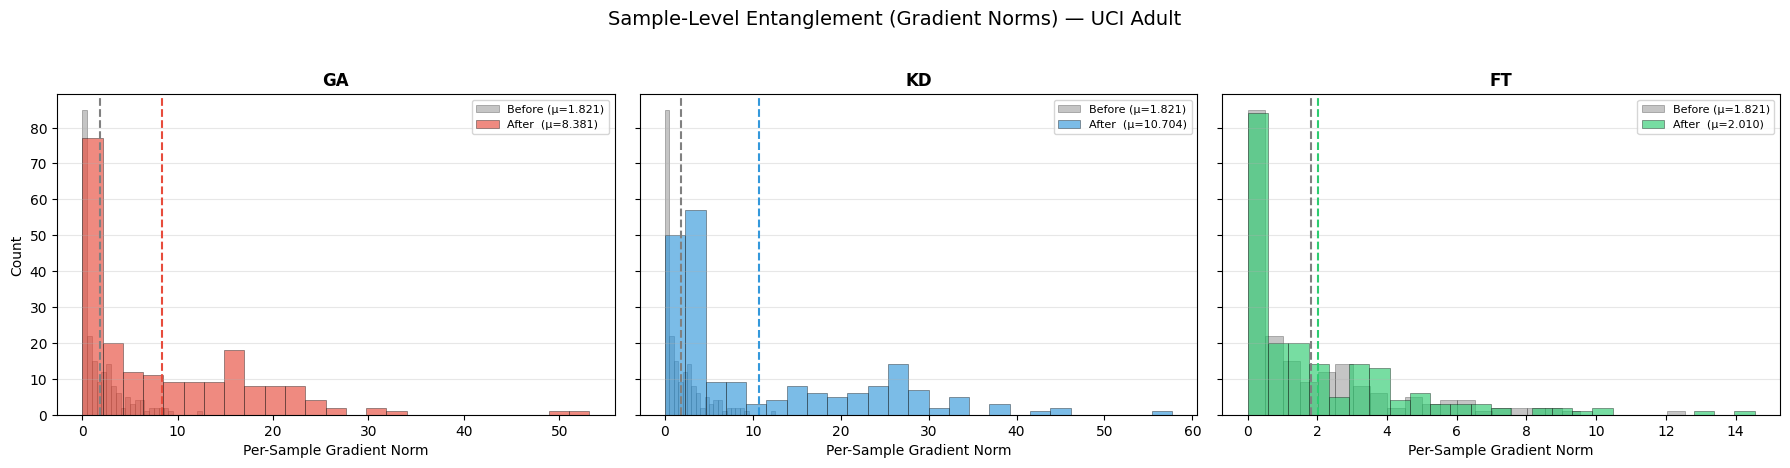

,Dataset,Method,Mean Grad-Norm Before,Mean Grad-Norm After,Δ Mean,Std Before,Std After,Δ Std
0,UCI Adult,Gradient Ascent,1.8210,8.3811,+6.5601,2.2951,9.3523,+7.0573
1,UCI Adult,Knowledge Distillation,1.8210,10.7040,+8.8831,2.2951,12.1459,+9.8508
2,UCI Adult,Fine-Tuning,1.8210,2.0095,+0.1886,2.2951,2.5694,+0.2744


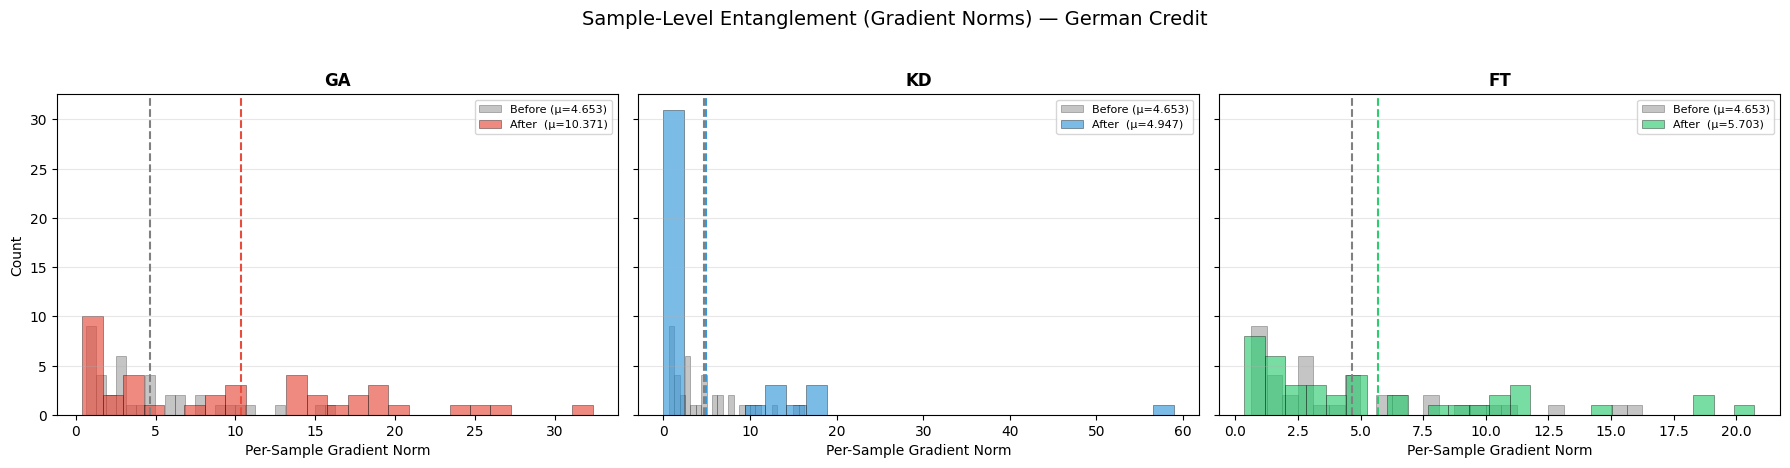

,Dataset,Method,Mean Grad-Norm Before,Mean Grad-Norm After,Δ Mean,Std Before,Std After,Δ Std
0,German Credit,Gradient Ascent,4.6527,10.3707,+5.7181,4.0493,8.6418,+4.5925
1,German Credit,Knowledge Distillation,4.6527,4.9474,+0.2947,4.0493,10.3379,+6.2886
2,German Credit,Fine-Tuning,4.6527,5.7030,+1.0503,4.0493,5.4644,+1.4151


In [ ]:
def plot_sample_level_entanglement(ent_results, dataset_name):
    """Overlapping histograms of per-sample gradient norms before/after for each method."""
    methods = list(ent_results.keys())
    meth_colors = {'Gradient Ascent': '#e74c3c',
                   'Knowledge Distillation': '#3498db',
                   'Fine-Tuning': '#2ecc71'}
    meth_short = {'Gradient Ascent': 'GA', 'Knowledge Distillation': 'KD', 'Fine-Tuning': 'FT'}

    fig, axes = plt.subplots(1, len(methods), figsize=(6 * len(methods), 4.5), sharey=True)
    if len(methods) == 1: axes = [axes]

    stats_rows = []
    for midx, m in enumerate(methods):
        ax = axes[midx]
        sb = ent_results[m]['sample_before']
        sa = ent_results[m]['sample_after']
        col = meth_colors[m]

        ax.hist(sb, bins=25, alpha=0.45, color='gray', edgecolor='black',
                linewidth=0.4, label=f'Before (μ={sb.mean():.3f})')
        ax.hist(sa, bins=25, alpha=0.65, color=col, edgecolor='black',
                linewidth=0.4, label=f'After  (μ={sa.mean():.3f})')

        ax.axvline(sb.mean(), ls='--', color='gray',  lw=1.5)
        ax.axvline(sa.mean(), ls='--', color=col,     lw=1.5)
        ax.set_xlabel('Per-Sample Gradient Norm', fontsize=10)
        if midx == 0:
            ax.set_ylabel('Count', fontsize=10)
        ax.set_title(f'{meth_short[m]}', fontsize=12, fontweight='bold')
        ax.legend(fontsize=8)
        ax.grid(axis='y', alpha=0.3)

        delta_mean = sa.mean() - sb.mean()
        delta_std  = sa.std()  - sb.std()
        stats_rows.append({
            'Dataset': dataset_name, 'Method': m,
            'Mean Grad-Norm Before': sb.mean(),
            'Mean Grad-Norm After':  sa.mean(),
            'Δ Mean': delta_mean,
            'Std Before': sb.std(),
            'Std After':  sa.std(),
            'Δ Std': delta_std,
        })

    fig.suptitle(f'Sample-Level Entanglement (Gradient Norms) — {dataset_name}',
                 fontsize=14, y=1.03)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Sample_Entanglement_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

    df = pd.DataFrame(stats_rows)
    display(df.style.format({
        'Mean Grad-Norm Before':'{:.4f}', 'Mean Grad-Norm After':'{:.4f}',
        'Δ Mean':'{:+.4f}', 'Std Before':'{:.4f}', 'Std After':'{:.4f}', 'Δ Std':'{:+.4f}',
    }).set_caption(f"Sample-Level Entanglement Statistics — {dataset_name}"))

plot_sample_level_entanglement(ent_adult,  'UCI Adult')
plot_sample_level_entanglement(ent_german, 'German Credit')

### 12.8 Cross-Dataset Entanglement Heatmap (Party-Level Δρ)

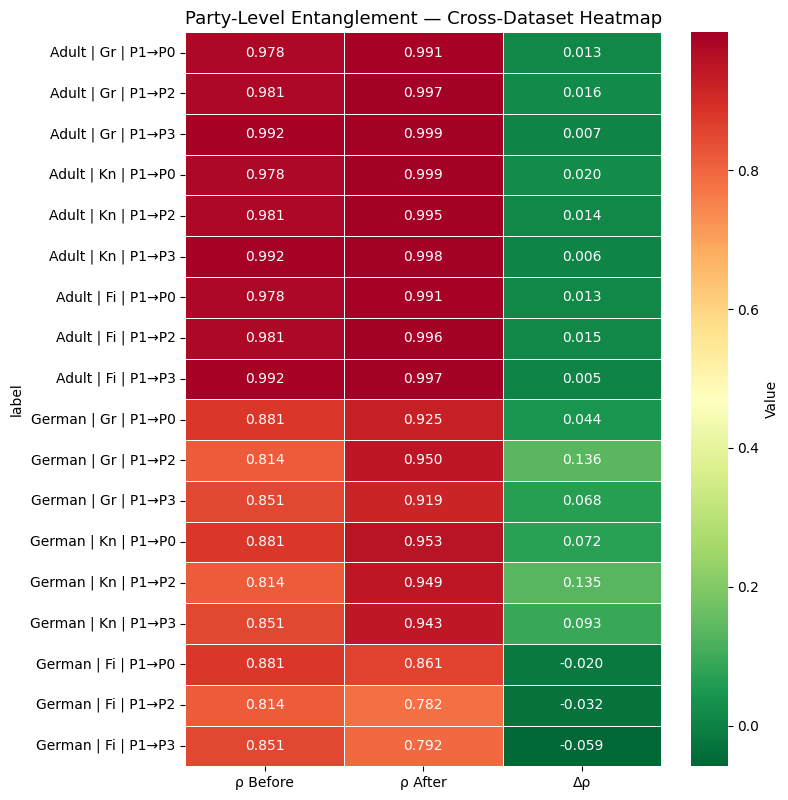

In [ ]:
def entanglement_heatmap(ent_adult, ent_german, target_k=1):
    """Heatmap of ρ_after for each method × party pair × dataset."""
    rows = []
    for ds_name, ent in [('Adult', ent_adult), ('German', ent_german)]:
        for m in ent:
            for j in sorted(ent[m]['party_after'].keys()):
                rb = ent[m]['party_before'][j]['rho']
                ra = ent[m]['party_after'][j]['rho']
                rows.append({
                    'label': f'{ds_name} | {m[:2]} | P{target_k}→P{j}',
                    'ρ Before': rb,
                    'ρ After':  ra,
                    'Δρ':       ra - rb,
                })
    df = pd.DataFrame(rows).set_index('label')

    fig, ax = plt.subplots(figsize=(8, max(3, len(df) * 0.45)))
    sns.heatmap(df, annot=True, fmt='.3f', cmap='RdYlGn_r', linewidths=0.5,
                ax=ax, cbar_kws={'label': 'Value'})
    ax.set_title('Party-Level Entanglement — Cross-Dataset Heatmap', fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Entanglement_Heatmap_Cross_Dataset.png", dpi=150, bbox_inches='tight')
    plt.show()

entanglement_heatmap(ent_adult, ent_german)

### 12.9 Entanglement Risk Transition Matrix

In [ ]:
def risk_transition_table(ent_results, dataset_name, target_k=1):
    """Show how risk labels change before→after unlearning (party + feature level)."""
    print(f"\n{'='*80}")
    print(f"  RISK TRANSITION SUMMARY — {dataset_name}")
    print(f"{'='*80}")

    # ---- Party-level ----
    print(f"\n  Party-Level (target = P_{target_k})")
    print(f"  {'Method':<30} {'Pair':<15} {'Before':<10} {'After':<10} {'Transition'}")
    print(f"  {'─'*75}")
    for m in ent_results:
        for j in sorted(ent_results[m]['party_before'].keys()):
            rb = ent_results[m]['party_before'][j]['risk']
            ra = ent_results[m]['party_after'][j]['risk']
            arrow = '→'
            if rb != ra:
                arrow = '↓' if ['LOW','MEDIUM','HIGH'].index(ra) < ['LOW','MEDIUM','HIGH'].index(rb) else '↑'
            print(f"  {m:<30} P_{target_k}→P_{j:<10} {rb:<10} {ra:<10} {rb} {arrow} {ra}")

    # ---- Feature-level ----
    print(f"\n  Feature-Level (P_{target_k} features)")
    print(f"  {'Method':<30} {'Feature':<20} {'Before':<10} {'After':<10} {'Transition'}")
    print(f"  {'─'*80}")
    for m in ent_results:
        fb = ent_results[m]['feat_before']
        fa = ent_results[m]['feat_after']
        for i in range(len(fb)):
            rb = fb[i]['risk']
            ra = fa[i]['risk']
            arrow = '→'
            if rb != ra:
                arrow = '↓' if ['LOW','MEDIUM','HIGH'].index(ra) < ['LOW','MEDIUM','HIGH'].index(rb) else '↑'
            print(f"  {m:<30} {fb[i]['name']:<20} {rb:<10} {ra:<10} {rb} {arrow} {ra}")
    print(f"{'='*80}")

risk_transition_table(ent_adult,  'UCI Adult')
risk_transition_table(ent_german, 'German Credit')


  RISK TRANSITION SUMMARY — UCI Adult

  Party-Level (target = P_1)
  Method                         Pair            Before     After      Transition
  ───────────────────────────────────────────────────────────────────────────
  Gradient Ascent                P_1→P_0          HIGH       HIGH       HIGH → HIGH
  Gradient Ascent                P_1→P_2          HIGH       HIGH       HIGH → HIGH
  Gradient Ascent                P_1→P_3          HIGH       HIGH       HIGH → HIGH
  Knowledge Distillation         P_1→P_0          HIGH       HIGH       HIGH → HIGH
  Knowledge Distillation         P_1→P_2          HIGH       HIGH       HIGH → HIGH
  Knowledge Distillation         P_1→P_3          HIGH       HIGH       HIGH → HIGH
  Fine-Tuning                    P_1→P_0          HIGH       HIGH       HIGH → HIGH
  Fine-Tuning                    P_1→P_2          HIGH       HIGH       HIGH → HIGH
  Fine-Tuning                    P_1→P_3          HIGH       HIGH       HIGH → HIGH

  Feature-Leve

### 12.10 Comprehensive Entanglement Summary & Interpretation

In [ ]:
def final_entanglement_summary(ent_adult, ent_german):
    """Aggregate statistics across all levels and datasets."""
    print("=" * 90)
    print("  FINAL ENTANGLEMENT ANALYSIS SUMMARY")
    print("=" * 90)

    for ds_name, ent in [('UCI Adult', ent_adult), ('German Credit', ent_german)]:
        print(f"\n  ── {ds_name} ──")
        print(f"  {'Method':<30} {'Avg ρ_party':<14} {'Avg ρ_feat':<14} "
              f"{'ΔGradNorm':<14} {'Interpretation'}")
        print(f"  {'─'*85}")
        for m in ent:
            # party-level avg ρ after
            party_rhos = [ent[m]['party_after'][j]['rho']
                          for j in ent[m]['party_after']]
            avg_party = np.mean(party_rhos)

            # feature-level avg ρ_overall after
            feat_rhos = [r['rho_overall'] for r in ent[m]['feat_after']]
            avg_feat = np.mean(feat_rhos)

            # sample-level
            delta_gn = ent[m]['sample_after'].mean() - ent[m]['sample_before'].mean()

            if avg_party > TAU_HIGH:
                interp = "HIGH entanglement persists"
            elif avg_party > TAU_LOW:
                interp = "Moderate entanglement"
            else:
                interp = "Low / negligible coupling"

            print(f"  {m:<30} {avg_party:<14.4f} {avg_feat:<14.4f} "
                  f"{delta_gn:<+14.4f} {interp}")

    print(f"\n{'='*90}")
    print("""
  KEY OBSERVATIONS:

  PARTY-LEVEL:
    • ρ_{k→j} close to 1 means party k's features are tightly coupled with
      party j's encoder through the top model's nonlinearities.
    • Gradient Ascent tends to perturb weights globally, which can increase
      or decrease cross-party ρ unpredictably.
    • Knowledge Distillation builds a fresh student — the student never saw
      the target party's data, so ρ reflects only the new model's structure.
    • Fine-Tuning overwrites the forget-set signal; the coupling usually
      stays similar because the model architecture is unchanged.

  FEATURE-LEVEL:
    • ρ_self (intra-party) captures how much a single feature drives the
      party's own encoder. Features with high ρ_self are "anchor" features.
    • ρ_cross (per-feature column norm / Frobenius) shows which features
      carry the most coupling with other parties.

  SAMPLE-LEVEL:
    • Per-sample gradient norms dropping after unlearning means the model
      responds less strongly to those samples — a sign of effective unlearning.
    • Gradient Ascent should increase the gradient norm (loss is being
      maximised), while KD and FT should decrease it (model has forgotten).
""")

final_entanglement_summary(ent_adult, ent_german)

  FINAL ENTANGLEMENT ANALYSIS SUMMARY

  ── UCI Adult ──
  Method                         Avg ρ_party    Avg ρ_feat     ΔGradNorm      Interpretation
  ─────────────────────────────────────────────────────────────────────────────────────
  Gradient Ascent                0.9955         0.4706         +6.5601        HIGH entanglement persists
  Knowledge Distillation         0.9970         0.4115         +8.8831        HIGH entanglement persists
  Fine-Tuning                    0.9947         0.4720         +0.1886        HIGH entanglement persists

  ── German Credit ──
  Method                         Avg ρ_party    Avg ρ_feat     ΔGradNorm      Interpretation
  ─────────────────────────────────────────────────────────────────────────────────────
  Gradient Ascent                0.9314         0.4294         +5.7181        HIGH entanglement persists
  Knowledge Distillation         0.9486         0.4381         +0.2947        HIGH entanglement persists
  Fine-Tuning                    

## 13. References

1. **Varshney et al. (2025)** — *VFU-KD / VFU-GA: Knowledge Distillation and Gradient Ascent for Vertical Federated Unlearning.* Proposes client, feature, and sample unlearning in VFL using KD and GA. Introduces Jacobian-based feature entanglement analysis (Algorithm 5).
2. **Su et al. (2023)** — *KNOT: Knowledge Distillation-based Teacher-Student Unlearning Framework for Horizontal FL.*
3. **Yuan et al. (2023)** — *FRU: Fast and Rapid Unlearning via Channel Pruning and Fine-Tuning.*
4. **Gu et al. (2024)** — *Few-shot Label Unlearning in VFL via Mixup + Gradient Ascent.*
5. **Deng et al. (2023)** — *VFU-LR: Constraint-based Unlearning for Logistic Regression in VFL.*
6. **Bourtoule et al. (2021)** — *SISA: Machine Unlearning via Sharding and Slicing.*
7. **Liu et al. (2021)** — *FedEraser: Enabling Efficient Client-Level Data Removal from Federated Learning.*
8. **Shokri et al. (2017)** — *Membership Inference Attacks Against Machine Learning Models (S&P).*
9. **Geiping et al. (2020)** — *Inverting Gradients — How Easy is it to Break Privacy in Federated Learning? (NeurIPS).* Gradient leakage and reconstruction attacks.